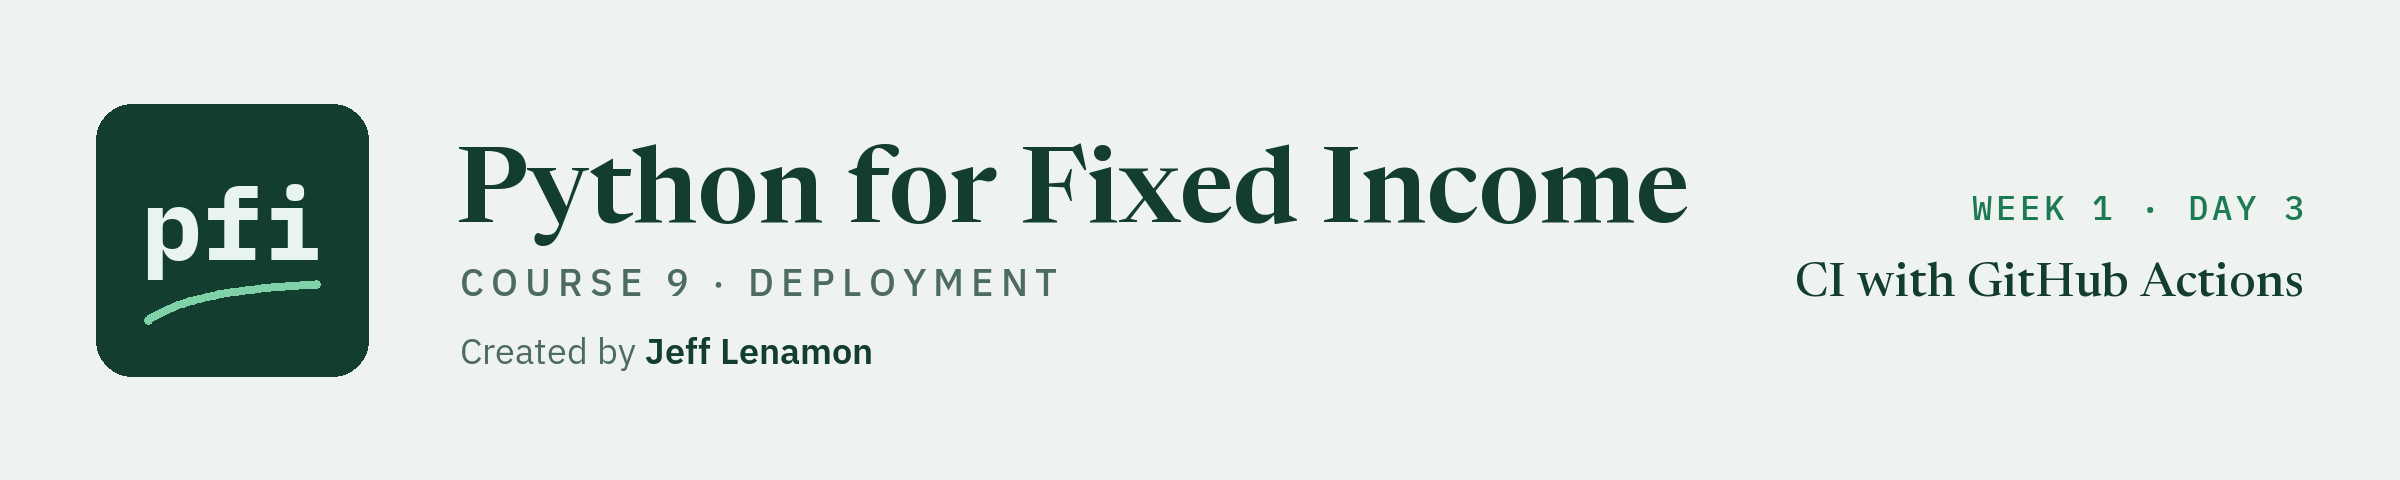

# CI with GitHub Actions

Week 1, Day 3. Today GitHub runs your tests on a fresh Linux machine on every push and pull request: you write the workflow file, read its first bash, catch YAML's traps before they run, and read the course's own runs on GitHub, two red and one green.

**Recorded transcripts:** `course9_transcripts/`, what the platforms printed when the course ran the same steps on its own accounts, recorded once and masked (account names, URLs, ids); shown, never re-run.

**Data:** `bondmath_excel_reference.csv` (306 bond cases) and `bondmath_excel_reference_tvm.csv` (153 cases), Excel's own results for Course 2's bond math, which `test_bondmath.py` compares with: **synthetic** bonds, made by the course in Excel, MIT with the code.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course09_deployment/week1/day3/03_ci_with_github_actions.ipynb)

On day 2 a pull request was a branch plus a conversation, and its review was a person reading the diff. A person can read a diff; a person cannot run every test on every change, on a machine set up from nothing, every time. That is what **continuous integration** (CI) does: a machine nobody owns checks out the commit, installs what the code needs, and runs the tests, then puts a green tick or a red cross beside the commit and the pull request.

Today you write that machine's instructions, a **workflow file**, with `deploykit`; read it line by line, including the first **bash** of the series; catch the YAML mistakes that run without an error; and see what changes when the tests run on Linux instead of your Windows laptop. Then you read what GitHub printed when the course pushed the same file to its throwaway repo: **red, red, then green**, each for a reason you can read in the log.

**The rules for deployed code, as on day 1.** Nothing goes public until `public_scan` is empty. The bonds are synthetic, and a real company appears only as the author of a document. A service returns figures with their as-of date and never a view on any security or rate. Your firm's policy comes first: the free accounts are personal accounts for learning.

**Rows.** No model is fitted or served today, and no cell reaches GitHub. The data are Course 2's two reference files, which travel with `test_bondmath.py`, and eight **recorded transcripts**: what Git and GitHub's command line printed when the course fixed the demo repo's line endings and ran its first workflow, recorded once and masked.

Today you will:

1. Say what CI is, and where GitHub Actions came from.
2. Write the course's workflow with `workflow_text`, and read it as a table with `workflow_steps`.
3. Read the first bash of the series, line by line.
4. Catch YAML's traps with `check_workflow`.
5. See where Linux is not Windows: line endings, and the case of a file name.
6. Run the tests on two Pythons with a matrix.
7. Push the workflow, and read the course's red, red, and green runs.
8. Name how secrets reach a workflow, and how the log hides them.

Q. Set up today's work folder: the thread settings, the quiet-loading settings, the seed, the course's files, and a fresh work folder.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course09_deployment/requirements.txt
NEEDED = {
    "bs4": "beautifulsoup4==4.15.0",
    "fastapi": "fastapi==0.143.0",
    "gradio": "gradio==6.30.0",
    "httpx": "httpx==0.28.1",
    "huggingface_hub": "huggingface-hub==1.33.0",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "joblib": "joblib==1.6.0",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "mcp": "mcp==2.3.0",
    "numpy": "numpy==2.5.3",
    "agents": "openai-agents==0.23.1",
    "openai": "openai==3.26.0",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pydantic": "pydantic==2.13.5",
    "pypdf": "pypdf==6.19.0",
    "pypdfium2": "pypdfium2==5.14.0",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "yaml": "pyyaml==6.0.3",
    "requests": "requests==2.34.2",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "sentence_transformers": "sentence-transformers==6.1.0",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "streamlit": "streamlit==1.65.0",
    "tensorflow": "tensorflow==2.21.0",
    "torch": "torch==2.14.1",
    "transformers": "transformers==5.19.0",
    "uvicorn": "uvicorn==0.54.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

37 packages checked, all present


In [2]:
# today's setup: thread settings, quiet loading, the modules, the seed, the course data, a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, or PyTorch is imported: if you ran another cell first,
# restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# the model libraries print download bars and notices; these lines must run before they are imported
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("torch", "torch"), ("transformers", "transformers"), ("sentence_transformers", "sentence-transformers"), ("openai", "openai"), ("agents", "openai-agents"), ("mcp", "mcp"), ("pydantic", "pydantic"), ("bs4", "beautifulsoup4"), ("dotenv", "python-dotenv"), ("openpyxl", "openpyxl"), ("pytest", "pytest"), ("fastapi", "fastapi"), ("uvicorn", "uvicorn"), ("gradio", "gradio"), ("streamlit", "streamlit"), ("yaml", "pyyaml"), ("joblib", "joblib")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course09_deployment/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "torch": "2.14.1", "transformers": "5.19.0", "sentence-transformers": "6.1.0", "openai": "3.26.0", "openai-agents": "0.23.1", "mcp": "2.3.0", "pydantic": "2.13.5", "pytest": "9.1.1", "fastapi": "0.143.0", "gradio": "6.30.0", "streamlit": "1.65.0"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name].split("+")[0] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "holdings.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course9_03_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["bondmath_excel_reference.csv", "bondmath_excel_reference_tvm.csv", "course9_transcripts/day03/git_eol_before.txt", "course9_transcripts/day03/git_normalise_stat.txt", "course9_transcripts/day03/git_eol_after.txt", "course9_transcripts/day03/git_push_workflow.txt", "course9_transcripts/day03/gh_run_red.txt", "course9_transcripts/day03/gh_run_red_2.txt", "course9_transcripts/day03/gh_run_green.txt", "course9_transcripts/day03/gh_run_list.txt"]
for name in DATA_FILES:
    (work / name).parent.mkdir(parents=True, exist_ok=True)
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, torch 2.14.1, transformers 5.19.0, sentence-transformers 6.1.0, openai 3.26.0, openai-agents 0.23.1, mcp 2.3.0, pydantic 2.13.5, pytest 9.1.1, fastapi 0.143.0, gradio 6.30.0, streamlit 1.65.0
Work folder: pfi_course9_03_740ctlyw, in your temp folder
Data files from the data folder of the course repo: bondmath_excel_reference.csv, bondmath_excel_reference_tvm.csv, course9_transcripts/day03/git_eol_before.txt, course9_transcripts/day03/git_normalise_stat.txt, course9_transcripts/day03/git_eol_after.txt, course9_transcripts/day03/git_push_workflow.txt, course9_transcripts/day03/gh_run_red.txt, course9_transcripts/day03/gh_run_red_2.txt, course9_transcripts/day03/gh_run_green.txt, course9_transcripts/day03/gh_run_list.txt
SEED = 42


Q. Write the earlier courses' modules today needs, unchanged: `bondmath.py`, `marketdata.py`, `plotkit.py`.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Writing marketdata.py


In [5]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


Q. Write `deploykit.py` and `test_deploykit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [6]:
%%writefile deploykit.py
"""deploykit: shipping your fixed income code, from a public repo to a public app, and keeping it running.

Written day by day in Python for Fixed Income, Course 9: Deployment.

Conventions, the same in every function:
- A server installs only what its code imports. So this module imports the standard library at the top, FastAPI,
  pydantic, and bondmath (standard library only) from day 6, and everything else (pandas, PyYAML, joblib, requests,
  Gradio, Streamlit, agentkit) inside the functions that need it. A service built from deploykit needs fastapi and
  nothing more.
- Nothing here holds or prints a secret. A scan reports where a key-like string is, its kind, its first three
  characters, and its length, never the value.
- Units are in names: price_per_100 and dv01_per_100 per 100 of face, yield_pct in percent, latency_ms in
  milliseconds, sizes in bytes or in MB of 1024 x 1024 bytes, money in US dollars.
- Every served figure states its as-of date. A service returns, refuses, and logs; nothing here is a view on any
  security, issuer, or rate.
"""
from __future__ import annotations  # type hints are read as text, so pandas is imported only where it is used

import re  # the key, email, and address patterns
import subprocess  # running git
from pathlib import Path

# printed by a live-deploy cell when no deployment of your own is set: the cell then does nothing
NO_DEPLOY_MESSAGE = ("No deployment of your own is set in my_bondmath\\.env (MY_SERVICE_URL, MY_SPACE_ID, or HF_TOKEN "
                     "not loaded), so this cell does nothing. After your own deploy, add the line and run it again.")
# what a masked transcript puts in place of each private item
MASKS = {"name": "student", "team": "student-projects", "email": "student@example.com", "id": "<id>", "ip": "<ip>",
         "host": "student"}
# the only email address the course's files and outputs may hold
ALLOWED_EMAIL = "student@example.com"
# key-like strings, each with a minimum length after its prefix so a word in prose does not trip it
KEY_PATTERNS = {
    "sk-or-": re.compile(r"\bsk-or-[A-Za-z0-9-]{8,}"),
    "sk-": re.compile(r"\bsk-(?!or-)[A-Za-z0-9_-]{16,}"),
    "hf_": re.compile(r"\bhf_[A-Za-z0-9]{16,}"),
    "ghp_": re.compile(r"\bghp_[A-Za-z0-9]{16,}"),
    "github_pat_": re.compile(r"\bgithub_pat_[A-Za-z0-9_]{16,}"),
    "vercel_": re.compile(r"\bvercel_[A-Za-z0-9]{16,}"),
    "Bearer ": re.compile(r"\bBearer\s+[A-Za-z0-9._~+/-]{12,}"),
}
_EMAIL = re.compile(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}")
_IPV4 = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")
_PLATFORM_HOST = re.compile(r"\b[a-z0-9][a-z0-9-]*\.(vercel\.app|hf\.space)\b", re.IGNORECASE)
_PLATFORM_ID = re.compile(r"\b(?:dpl|prj|team)_[A-Za-z0-9]{6,}\b")
# Vercel's ids printed without a prefix: a deployment in an inspect address (vercel.com/<team>/<project>/<id>) or in
# "deployment (<id>)", a deployment or project in the CLI's JSON, and a request id (letters and digits, a 13-digit
# time in milliseconds, hexadecimal)
_LONG_ID = r"(?=[A-Za-z0-9]*\d)[A-Za-z0-9]{20,}"
_VERCEL_INSPECT = re.compile(r"(vercel\.com/[^/\s]+/[^/\s]+/)" + _LONG_ID + r"\b")
_VERCEL_DEPLOYMENT = re.compile(r"(deployment \()" + _LONG_ID + r"(\))")
_VERCEL_JSON_ID = re.compile(r'("(?:deploymentId|projectId)": ?")[A-Za-z0-9_]{12,}(")')
_VERCEL_REQUEST = re.compile(r"\b[a-z0-9]{3,}-\d{13}-[0-9a-f]{8,}\b")
# a file that holds environment values; .env.example holds names only and may be published
_ENV_FILE = re.compile(r"^\.env(?!\.example$)")
MB = 1024 * 1024


def run_git(folder, *args: str) -> str:
    """Run one git command in a folder and return what it printed.

    Inputs: folder, the repository's folder; args, the command's words, for example "log", "--oneline", "-3".
    Output: git's standard output as text.
    Convention: the same as typing git -C folder ... in PowerShell. Raises RuntimeError with git's own message
    (its standard error) when the command fails, so a failed push or merge is never silent.
    """
    result = subprocess.run(["git", "-C", str(folder), *args], capture_output=True, text=True, encoding="utf-8")
    if result.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed: {result.stderr.strip()}")
    return result.stdout


def _hidden(value: str) -> str:
    """How a scan names a match without showing it: its first three characters and its length."""
    return f"starts {value[:3]!r}, {len(value)} characters"


def _text_of(path: Path) -> str | None:
    """A file's text, or None for a binary file (one that holds a zero byte)."""
    data = path.read_bytes()
    if b"\x00" in data[:8192]:
        return None
    return data.decode("utf-8", errors="replace")


def _files(folder: Path) -> list[Path]:
    """Every file under a folder, at any depth, without Git's own .git folder, in a fixed order."""
    return sorted(p for p in folder.rglob("*") if p.is_file() and ".git" not in p.relative_to(folder).parts)


def public_scan(folder, max_mb: float = 5.0):
    """Everything in a folder that must not go public, one row per problem.

    Inputs: folder, the folder you are about to push to a public repo; max_mb, the largest file allowed, in MB of
    1024 x 1024 bytes.
    Output: a DataFrame with columns file (relative to the folder), line (0 for the whole file), kind, and detail.
    Kinds: env_file (a .env file at any depth; .env.example, which holds names only, is allowed), key_like (a match
    of KEY_PATTERNS), email (any address but student@example.com), large_file. Empty means safe to publish.
    Convention: the detail never holds a matched value, only its first three characters and its length. Git's .git
    folder is not scanned (its history is checked by what you commit, not by this scan).
    """
    import pandas as pd

    folder = Path(folder)
    rows = []
    for path in _files(folder):
        name = path.relative_to(folder).as_posix()
        if _ENV_FILE.match(path.name):
            rows.append({"file": name, "line": 0, "kind": "env_file", "detail": "an environment file; never published"})
        size = path.stat().st_size
        if size > max_mb * MB:
            rows.append({"file": name, "line": 0, "kind": "large_file",
                         "detail": f"{size / MB:.1f} MB, over {max_mb:g} MB (MB = 1024 x 1024 bytes)"})
        text = _text_of(path)
        if text is None:
            continue
        for number, line in enumerate(text.splitlines(), start=1):
            for kind, pattern in KEY_PATTERNS.items():
                for found in pattern.findall(line):
                    rows.append({"file": name, "line": number, "kind": "key_like",
                                 "detail": f"{kind} pattern, {_hidden(found)}"})
            for found in _EMAIL.findall(line):
                if found.lower() != ALLOWED_EMAIL:
                    rows.append({"file": name, "line": number, "kind": "email", "detail": f"an address, {_hidden(found)}"})
    return pd.DataFrame(rows, columns=["file", "line", "kind", "detail"])


def mask_transcript(text: str, names: list[str]) -> str:
    """A terminal transcript with every private item replaced by the course's masks, safe to share.

    Inputs: text, what a command printed; names, the account names, team slugs, and other words to hide (read on
    the machine that ran the command, never written to a file).
    Output: the text with each name (any case) as "student", every email but student@example.com as
    student@example.com, each IPv4 address as <ip>, the host of every *.vercel.app and *.hf.space address as
    student, and Vercel's ids as <id>: deployment, project, and team ids (dpl_..., prj_..., team_...), the ids the
    CLI prints without a prefix (an inspect address's last part, "deployment (...)", deploymentId and projectId in
    its JSON), and request ids (for example abc12-1791807391930-0123abcd).
    Convention: longer names are replaced first, so a team slug that holds a user name is masked whole.
    """
    for name in sorted((n for n in names if n), key=len, reverse=True):
        text = re.sub(re.escape(name), MASKS["name"], text, flags=re.IGNORECASE)
    text = _EMAIL.sub(lambda m: m.group(0) if m.group(0).lower() == ALLOWED_EMAIL else MASKS["email"], text)
    text = _IPV4.sub(MASKS["ip"], text)
    text = _PLATFORM_HOST.sub(lambda m: f"{MASKS['host']}.{m.group(1).lower()}", text)
    text = _VERCEL_INSPECT.sub(lambda m: m.group(1) + MASKS["id"], text)
    text = _VERCEL_DEPLOYMENT.sub(lambda m: m.group(1) + MASKS["id"] + m.group(2), text)
    text = _VERCEL_JSON_ID.sub(lambda m: m.group(1) + MASKS["id"] + m.group(2), text)
    text = _VERCEL_REQUEST.sub(MASKS["id"], text)
    return _PLATFORM_ID.sub(MASKS["id"], text)


def show_transcript(path, max_lines: int = 40) -> None:
    """Print a masked transcript the course recorded: one line saying what it is, the command, then the text.

    Inputs: path, a file of data/course9_transcripts/dayNN/; max_lines, the most lines of text to print.
    Output: none; prints. A longer text is cut, and the cut is stated with the number of lines not shown.
    Convention: the file's first three lines are its header (recorded:, command:, masked:).
    """
    lines = Path(path).read_text(encoding="ascii").splitlines()
    header = dict(line.split(": ", 1) for line in lines[:3])
    body = lines[3:]
    print(f"Recorded {header['recorded']} on the course's own account; account names, URLs, and ids masked to "
          f"`student`.")
    print(f"> {header['command']}")
    for line in body[:max_lines]:
        print(line)
    if len(body) > max_lines:
        print(f"[... {len(body) - max_lines} more lines not shown]")


def diff_table(folder, base: str, head: str):
    """What a change adds and removes, file by file: the table a reviewer reads before the diff itself.

    Inputs: folder, the repository; base and head, two commits, branches, or tags (for example "main" and
    "fix-day-count").
    Output: a DataFrame with columns file, added, removed (lines), from git diff --numstat base head. A binary
    file shows 0 and 0.
    """
    import pandas as pd

    rows = []
    for line in run_git(folder, "diff", "--numstat", base, head).splitlines():
        added, removed, name = line.split("\t", 2)
        rows.append({"file": name, "added": int(added) if added != "-" else 0,
                     "removed": int(removed) if removed != "-" else 0})
    return pd.DataFrame(rows, columns=["file", "added", "removed"])


def branch_table(folder):
    """Every local branch beside main: its last commit's subject, and how far it is ahead of and behind main.

    Input: folder, the repository (it must have a branch named main).
    Output: a DataFrame with columns branch, last_subject, ahead (commits on the branch not on main), behind
    (commits on main not on the branch), one row per branch in name order, main itself included (0 and 0).
    """
    import pandas as pd

    rows = []
    for branch in sorted(run_git(folder, "for-each-ref", "--format=%(refname:short)", "refs/heads").split()):
        subject = run_git(folder, "log", "-1", "--format=%s", branch).strip()
        behind, ahead = run_git(folder, "rev-list", "--left-right", "--count", f"main...{branch}").split()
        rows.append({"branch": branch, "last_subject": subject, "ahead": int(ahead), "behind": int(behind)})
    return pd.DataFrame(rows, columns=["branch", "last_subject", "ahead", "behind"])


def conflict_files(folder) -> list[str]:
    """The files a merge left in conflict, which you must read and resolve before you commit.

    Input: folder, the repository, in the middle of a merge that stopped.
    Output: the file names Git lists as unmerged (git diff --name-only --diff-filter=U), sorted; empty when there
    is no conflict.
    """
    return sorted(run_git(folder, "diff", "--name-only", "--diff-filter=U").split())

Writing deploykit.py


In [7]:
%%writefile test_deploykit.py
"""Tests for deploykit.py. Run in the folder that holds deploykit.py and the earlier modules:
python -m pytest -q test_deploykit.py

The tests use small inline data, temporary folders, a bare repository as a remote, a fake clock, and the ASGI test
client: never a course data file but the ones named, never the network, never a port but the one real server's,
and never a key. Every planted key is fake and built from pieces, so no file of the course holds a key-like string.
"""
import pytest

import deploykit

# a fake key of each kind, built from pieces at run time
FAKE_OPENROUTER = "sk-or-" + "FAKE" * 3
FAKE_HF = "hf" + "_" + "Fake" * 6
# an address that is not the course's, built from pieces so no file of the course holds one
OTHER_EMAIL = "someone" + "@" + "mail.example.org"


def test_run_git_raises_with_stderr(tmp_path):
    deploykit.run_git(tmp_path, "init", "-q")
    with pytest.raises(RuntimeError, match="git log failed"):
        deploykit.run_git(tmp_path, "log")


def test_public_scan_finds_env_file(tmp_path):
    (tmp_path / ".env").write_text("HF_TOKEN=\n")
    (tmp_path / ".env.example").write_text("HF_TOKEN=\n")
    (tmp_path / "bondmath.py").write_text("x = 1\n")
    found = deploykit.public_scan(tmp_path)
    assert found[["file", "kind"]].values.tolist() == [[".env", "env_file"]]


def test_public_scan_finds_key_like_without_printing_it(tmp_path):
    (tmp_path / "config").mkdir()
    (tmp_path / "config" / "settings.py").write_text(f'TOKEN = "{FAKE_HF}"\nKEY = "{FAKE_OPENROUTER}"\n')
    found = deploykit.public_scan(tmp_path)
    assert found["kind"].tolist() == ["key_like", "key_like"] and found["line"].tolist() == [1, 2]
    shown = found.to_string()
    assert FAKE_HF not in shown and FAKE_OPENROUTER not in shown and f"{len(FAKE_HF)} characters" in shown


def test_public_scan_allows_student_email(tmp_path):
    (tmp_path / "README.md").write_text(f"Questions: student@example.com\nAuthor: {OTHER_EMAIL}\n")
    found = deploykit.public_scan(tmp_path)
    assert found[["line", "kind"]].values.tolist() == [[2, "email"]]
    assert "someone" not in found.to_string()


def test_public_scan_large_file(tmp_path):
    (tmp_path / "big.bin").write_bytes(b"\x00" * (deploykit.MB + 1))
    found = deploykit.public_scan(tmp_path, max_mb=1.0)
    assert found[["file", "kind"]].values.tolist() == [["big.bin", "large_file"]]
    assert deploykit.public_scan(tmp_path, max_mb=2.0).empty


def test_mask_transcript_names_emails_hosts():
    raw = (f"To https://github.com/DeskUser/pfi-deploy-demo.git by {OTHER_EMAIL} from 203.0.113.7\n"
           "Production: https://pfi-bond-service-a1b2c3-deskusers-projects.vercel.app (dpl_AbCdEf123456)\n"
           "Space: https://deskuser-pfi-desk-brief.hf.space student@example.com\n")
    masked = deploykit.mask_transcript(raw, ["deskusers-projects", "deskuser"])
    assert "deskuser" not in masked.lower() and OTHER_EMAIL not in masked and "203.0.113.7" not in masked
    assert "dpl_" not in masked
    assert "github.com/student/pfi-deploy-demo.git" in masked and "student@example.com" in masked
    assert "https://student.vercel.app" in masked and "https://student.hf.space" in masked
    assert "<ip>" in masked and "<id>" in masked


def test_mask_transcript_vercel_ids_without_prefix():
    deployment = "8XyZ" + "aB3dE5fG7hJ9kL2mN4pQ6rS"
    request = "abc12-" + "1791807391930" + "-0123abcd"
    raw = (f"Inspect https://vercel.com/deskusers-projects/pfi-bond-service/{deployment}\n"
           f"Restored build cache from previous deployment ({deployment})\n"
           f'{{"id":"{request}","deploymentId":"{deployment}","projectId":"{deployment}"}}\n'
           "Read https://vercel.com/docs/functions/runtimes/python\n")
    masked = deploykit.mask_transcript(raw, ["deskusers-projects"])
    assert deployment not in masked and request not in masked
    assert masked.splitlines() == ["Inspect https://vercel.com/student/pfi-bond-service/<id>",
                                   "Restored build cache from previous deployment (<id>)",
                                   '{"id":"<id>","deploymentId":"<id>","projectId":"<id>"}',
                                   "Read https://vercel.com/docs/functions/runtimes/python"]


def make_repo(folder):
    """A repository on branch main with the course's Git settings and one commit of notes.txt."""
    deploykit.run_git(folder, "init", "-q", "-b", "main")
    deploykit.run_git(folder, "config", "user.name", "Course Student")
    deploykit.run_git(folder, "config", "user.email", "student@example.com")
    deploykit.run_git(folder, "config", "core.autocrlf", "false")
    (folder / "notes.txt").write_text("one\ntwo\nthree\n")
    deploykit.run_git(folder, "add", "notes.txt")
    deploykit.run_git(folder, "commit", "-q", "-m", "Start")
    return folder


def commit(folder, name, text, message):
    (folder / name).write_text(text)
    deploykit.run_git(folder, "add", name)
    deploykit.run_git(folder, "commit", "-q", "-m", message)


def test_diff_table_counts(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "change")
    commit(tmp_path, "notes.txt", "one\n2\nthree\nfour\n", "Edit notes")
    table = deploykit.diff_table(tmp_path, "main", "change")
    assert table.values.tolist() == [["notes.txt", 2, 1]]


def test_branch_table_ahead_behind(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "feature")
    commit(tmp_path, "a.txt", "a\n", "Add a")
    commit(tmp_path, "b.txt", "b\n", "Add b")
    deploykit.run_git(tmp_path, "switch", "-q", "main")
    commit(tmp_path, "c.txt", "c\n", "Add c on main")
    table = deploykit.branch_table(tmp_path).set_index("branch")
    assert table.loc["feature", ["ahead", "behind"]].tolist() == [2, 1]
    assert table.loc["feature", "last_subject"] == "Add b"
    assert table.loc["main", ["ahead", "behind"]].tolist() == [0, 0]


def test_conflict_files_lists_unmerged(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "theirs")
    commit(tmp_path, "notes.txt", "one\nTWO\nthree\n", "Upper case")
    deploykit.run_git(tmp_path, "switch", "-q", "main")
    commit(tmp_path, "notes.txt", "one\n2\nthree\n", "Digit")
    assert deploykit.conflict_files(tmp_path) == []
    with pytest.raises(RuntimeError, match="merge"):
        deploykit.run_git(tmp_path, "merge", "-q", "theirs")
    assert deploykit.conflict_files(tmp_path) == ["notes.txt"]

Writing test_deploykit.py


Q. Import the modules.

In [8]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata
import deploykit

# reload reads the file again, so that running this cell after a change picks up the change
importlib.reload(deploykit)

# the functions defined in deploykit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(deploykit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "deploykit" and not name.startswith("_")
             and not isinstance(obj, type)]
print(f"deploykit functions: {len(functions)}")

deploykit functions: 7


Q. Import `plotkit`, Course 4's chart and table helpers (you read this module; you do not write it), and set the course's chart style.

In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is day 2's. Today it copies Course 2's two reference files and the eight transcripts, writes the earlier modules unchanged, and `deploykit.py` and `test_deploykit.py` as they stood at the end of day 2: seven functions, 10 tests.

Q. Write `test_bondmath.py`, Course 2's tests for `bondmath`, unchanged: the tests the workflow will run.

In [10]:
%%writefile test_bondmath.py
"""Tests for bondmath.py.

Every expected value comes from Excel: the two reference CSV files in this folder, or a small hand
table whose values those files confirm. Run from this folder with:  python -m pytest
"""
import csv
import math  # used from week 3
from datetime import date  # used from week 2
from pathlib import Path

import pytest

import bondmath

# the reference files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_rows(file_name: str) -> list[dict]:
    """Read a reference CSV from this folder: one dict per row, every value a string."""
    with open(HERE / file_name, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


TVM = read_rows("bondmath_excel_reference_tvm.csv")


def tvm_rows(function: str) -> list[dict]:
    """The week 1 reference rows for one Excel function, for example "FV"."""
    rows = [row for row in TVM if row["function"] == function]
    assert rows, f"no {function} rows in the reference file"
    return rows


def test_future_value_matches_excel_fv():
    for row in tvm_rows("FV"):
        # the inputs, in course units
        amount, rate_pct = float(row["amount"]), float(row["rate_pct"])
        years, frequency = float(row["years"]), int(row["frequency"])
        result = bondmath.future_value(amount, rate_pct, years, frequency)
        # Excel's FV, with the amount entered as -amount, is positive
        assert result == pytest.approx(float(row["excel_value"]), abs=1e-6), row["case_id"]


def test_present_value_matches_excel_pv():
    for row in tvm_rows("PV"):
        amount, rate_pct = float(row["amount"]), float(row["rate_pct"])
        years, frequency = float(row["years"]), int(row["frequency"])
        result = bondmath.present_value(amount, rate_pct, years, frequency)
        # Excel's PV of a positive amount is negative (money paid now), so compare with minus the Excel value
        assert result == pytest.approx(-float(row["excel_value"]), abs=1e-6), row["case_id"]


def test_present_value_undoes_future_value():
    for frequency in (1, 2, 4):
        # grow 100 for 3 years at 5 percent, then discount it back
        grown = bondmath.future_value(100, 5.0, 3, frequency)
        assert bondmath.present_value(grown, 5.0, 3, frequency) == pytest.approx(100, abs=1e-9)


REFERENCE = read_rows("bondmath_excel_reference.csv")


def test_cash_flows_count_and_final_flow():
    flows = bondmath.cash_flows(6.0, 5, 2)
    # 5 years of half-year coupons is 10 cash flows
    assert len(flows) == 10
    # the first is a 3.00 coupon after half a year, the last is the coupon plus the face at 5 years
    assert flows[0] == pytest.approx((0.5, 3.0))
    assert flows[-1] == pytest.approx((5.0, 103.0))


def test_cash_flows_raises_on_part_periods():
    # 2.3 years is not a whole number of half years, so cash_flows must stop with a ValueError
    try:
        bondmath.cash_flows(6.0, 2.3, 2)
    except ValueError:
        return
    assert False, "cash_flows accepted 2.3 years at frequency 2"


def test_price_from_yield_matches_excel():
    # Excel's -PV with a coupon: a bond priced on a coupon date
    for row in tvm_rows("PV_BOND"):
        result = bondmath.price_from_yield(float(row["coupon_pct"]), float(row["rate_pct"]),
                                           float(row["years"]), int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]), abs=1e-6), row["case_id"]
    # Excel's PRICE on the rows that settle on a coupon date (no days accrued)
    coupon_date_rows = [row for row in REFERENCE if row["coupdaybs"] == "0"]
    assert coupon_date_rows, "no coupon-date rows in the reference file"
    for row in coupon_date_rows:
        frequency = int(row["frequency"])
        years = int(row["coupnum"]) / frequency
        result = bondmath.price_from_yield(float(row["coupon_pct"]), float(row["yield_pct"]), years, frequency)
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]


def test_convert_yield_matches_excel_effect_and_nominal():
    # EFFECT restates a rate compounded `frequency` times a year as an annually compounded rate
    for row in tvm_rows("EFFECT"):
        result = bondmath.convert_yield(float(row["rate_pct"]), int(row["frequency"]), 1)
        # Excel returns a decimal, bondmath a percent
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-9), row["case_id"]
    # NOMINAL goes the other way: from annual compounding to `frequency` times a year
    for row in tvm_rows("NOMINAL"):
        result = bondmath.convert_yield(float(row["rate_pct"]), 1, int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-9), row["case_id"]


def test_convert_yield_round_trip():
    # semiannual to quarterly and back gives the yield we started with
    quarterly = bondmath.convert_yield(6.0, 2, 4)
    assert bondmath.convert_yield(quarterly, 4, 2) == pytest.approx(6.0, abs=1e-12)


def test_yield_from_price_matches_excel():
    # Excel's RATE, times the frequency, is the annual yield as a decimal
    for row in tvm_rows("RATE"):
        result = bondmath.yield_from_price(float(row["coupon_pct"]), float(row["price"]),
                                           float(row["years"]), int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-6), row["case_id"]
    # Excel's YIELD on the coupon-date rows, already in percent in the reference file
    for row in REFERENCE:
        if row["coupdaybs"] != "0":
            continue
        frequency = int(row["frequency"])
        years = int(row["coupnum"]) / frequency
        result = bondmath.yield_from_price(float(row["coupon_pct"]), float(row["price"]), years, frequency)
        assert result == pytest.approx(float(row["yield_pct_from_price"]), abs=1e-6), row["case_id"]


def test_yield_raises_outside_bracket():
    # no yield between -5 and 100 percent gives a price of 1,000 or of 0.01
    with pytest.raises(ValueError):
        bondmath.yield_from_price(6.0, 1000.0, 5, 2)
    with pytest.raises(ValueError):
        bondmath.yield_from_price(6.0, 0.01, 5, 2)


def test_yield_round_trip():
    # price a bond from a yield, then solve the yield back from that price
    bond_price = bondmath.price_from_yield(5.25, 6.1, 7, 2)
    assert bondmath.yield_from_price(5.25, bond_price, 7, 2) == pytest.approx(6.1, abs=1e-8)


def test_par_bond_prices_at_100():
    # a coupon equal to the yield prices at 100 for every frequency and term
    for frequency in (1, 2, 4):
        for years in (1, 2, 5, 10, 30):
            assert bondmath.price_from_yield(5.5, 5.5, years, frequency) == pytest.approx(100, abs=1e-9)


def test_price_falls_as_yield_rises():
    # price a 10-year 6 percent bond at yields from 2 to 12 percent
    prices = [bondmath.price_from_yield(6.0, yield_pct, 10, 2) for yield_pct in (2, 4, 6, 8, 10, 12)]
    # every price is below the one before it
    for earlier, later in zip(prices, prices[1:]):
        assert later < earlier


def test_add_months_clamps_to_month_end():
    # 31 August back 6 months: 28 February, or 29 February in a leap year
    assert bondmath.add_months(date(2031, 8, 31), -6) == date(2031, 2, 28)
    assert bondmath.add_months(date(2032, 8, 31), -6) == date(2032, 2, 29)
    # 31 January forward 1 month
    assert bondmath.add_months(date(2027, 1, 31), 1) == date(2027, 2, 28)
    # a day every month has is kept, across a year end
    assert bondmath.add_months(date(2026, 11, 15), 3) == date(2027, 2, 15)


def test_coupon_dates_match_excel():
    for row in REFERENCE:
        settlement, maturity = date.fromisoformat(row["settlement"]), date.fromisoformat(row["maturity"])
        dates = bondmath.coupon_dates(settlement, maturity, int(row["frequency"]))
        # [0] is COUPPCD, [1] is COUPNCD, and the number of dates after [0] is COUPNUM
        assert dates[0] == date.fromisoformat(row["couppcd"]), row["case_id"]
        assert dates[1] == date.fromisoformat(row["coupncd"]), row["case_id"]
        assert len(dates) - 1 == int(row["coupnum"]), row["case_id"]


BASIS = {"0": "30/360", "1": "ACT/ACT"}  # Excel's basis number to bondmath's name


def bond_inputs(row: dict) -> tuple:
    """settlement, maturity, coupon_pct, yield_pct, frequency, basis from a reference row, in bondmath's units."""
    return (date.fromisoformat(row["settlement"]), date.fromisoformat(row["maturity"]),
            float(row["coupon_pct"]), float(row["yield_pct"]), int(row["frequency"]), BASIS[row["basis"]])


def test_days_30_360_rule_cases():
    # (start, end, expected days, the Excel function that confirms the value)
    cases = [
        (date(2026, 8, 16), date(2026, 9, 30), 44, "COUPDAYBS"),    # no rule applies
        (date(2027, 2, 28), date(2027, 3, 1), 1, "COUPDAYBS"),      # rule 1: last day of February counts as 30
        (date(2027, 2, 28), date(2028, 2, 29), 360, "YEARFRAC"),    # rule 2: both on the last day of February
        (date(2026, 8, 31), date(2026, 9, 30), 30, "COUPDAYBS"),    # rule 3: a 31st start counts as 30
        (date(2026, 7, 30), date(2026, 10, 31), 90, "COUPDAYBS"),   # rule 4: a 31st end after a 30th start
        (date(2026, 10, 15), date(2026, 10, 31), 16, "COUPDAYBS"),  # a 31st end after a 15th start stays 31
        (date(2027, 2, 28), date(2027, 3, 31), 31, "COUPDAYBS"),    # rule 1, and the 31st end stays 31
        (date(2026, 11, 15), date(2027, 2, 28), 103, "COUPDAYBS"),  # an end on 28 February is not changed
    ]
    for start, end, expected, source in cases:
        assert bondmath.days_30_360(start, end) == expected, (start, end)
        if source == "COUPDAYBS":
            # the same pair of dates appears in the reference file as previous coupon and settlement
            matches = [row for row in REFERENCE if row["basis"] == "0" and row["couppcd"] == start.isoformat()
                       and row["settlement"] == end.isoformat()]
            assert matches, f"no reference row with previous coupon {start} and settlement {end}"
            assert int(matches[0]["coupdaybs"]) == expected
        # the YEARFRAC value, YEARFRAC(start, end, 0) x 360 = 360, was checked in Excel by the reference tool


def test_coupon_period_days_match_excel():
    for row in REFERENCE:
        settlement, maturity, _, _, frequency, basis = bond_inputs(row)
        days_accrued, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity, frequency, basis)
        # A is COUPDAYBS under both bases
        assert days_accrued == int(row["coupdaybs"]), row["case_id"]
        if basis == "30/360":
            # E is COUPDAYS, and PRICE uses DSC = E - A
            assert days_in_period == int(row["coupdays"]), row["case_id"]
            assert days_to_next == int(row["coupdays"]) - int(row["coupdaybs"]), row["case_id"]
        else:
            # E is the actual length of the period, which PRICE uses (Excel's COUPDAYS with basis 1 can differ)
            period_start, period_end = date.fromisoformat(row["couppcd"]), date.fromisoformat(row["coupncd"])
            assert days_in_period == (period_end - period_start).days, row["case_id"]
            assert days_to_next == int(row["coupdaysnc"]), row["case_id"]


def test_accrued_matches_excel():
    for row in REFERENCE:
        settlement, maturity, coupon_pct, _, frequency, basis = bond_inputs(row)
        result = bondmath.accrued_interest(settlement, maturity, coupon_pct, frequency, basis)
        assert result == pytest.approx(float(row["accrued"]), abs=1e-9), row["case_id"]


def test_price_matches_excel():
    for row in REFERENCE:
        result = bondmath.price(*bond_inputs(row))
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]


def test_dirty_is_clean_plus_accrued():
    for row in REFERENCE:
        result = bondmath.dirty_price(*bond_inputs(row))
        # Excel's PRICE plus Excel's accrued formula
        assert result == pytest.approx(float(row["price"]) + float(row["accrued"]), abs=1e-6), row["case_id"]


def test_price_on_coupon_date_equals_week1():
    for row in REFERENCE:
        if row["coupdaybs"] != "0":
            continue
        settlement, maturity, coupon_pct, yield_pct, frequency, basis = bond_inputs(row)
        # on a coupon date the bond has a whole number of periods left
        years = int(row["coupnum"]) / frequency
        week1_price = bondmath.price_from_yield(coupon_pct, yield_pct, years, frequency)
        assert bondmath.price(settlement, maturity, coupon_pct, yield_pct, frequency, basis) == pytest.approx(
            week1_price, abs=1e-9), row["case_id"]


def test_final_period_matches_excel():
    final_period_rows = [row for row in REFERENCE if row["coupnum"] == "1"]
    assert final_period_rows, "no final-period rows in the reference file"
    for row in final_period_rows:
        # one coupon left: Excel prices it with simple interest
        result = bondmath.price(*bond_inputs(row))
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]


def test_yield_to_maturity_matches_excel():
    for row in REFERENCE:
        settlement, maturity, coupon_pct, _, frequency, basis = bond_inputs(row)
        # solve the yield from Excel's price, and compare with Excel's YIELD of that price
        result = bondmath.yield_to_maturity(settlement, maturity, coupon_pct, float(row["price"]), frequency, basis)
        assert result == pytest.approx(float(row["yield_pct_from_price"]), abs=1e-6), row["case_id"]


def test_macaulay_matches_excel_duration():
    for row in REFERENCE:
        result = bondmath.macaulay_duration(*bond_inputs(row))
        assert result == pytest.approx(float(row["duration"]), abs=1e-6), row["case_id"]


def test_modified_matches_excel_mduration():
    for row in REFERENCE:
        result = bondmath.modified_duration(*bond_inputs(row))
        assert result == pytest.approx(float(row["mduration"]), abs=1e-6), row["case_id"]


def test_dv01_matches_excel_formula():
    for row in REFERENCE:
        result = bondmath.dv01(*bond_inputs(row))
        # Excel: MDURATION x (PRICE + accrued) / 10000
        assert result == pytest.approx(float(row["dv01"]), abs=1e-8), row["case_id"]


def test_dv01_close_to_bump():
    for row in REFERENCE:
        if row["coupnum"] == "1":
            continue  # final period: simple interest, so the bump is not the same measure
        # Excel's PRICE 1 bp lower and 1 bp higher, half the difference
        bump = (float(row["price_down_1bp"]) - float(row["price_up_1bp"])) / 2
        assert bondmath.dv01(*bond_inputs(row)) == pytest.approx(bump, abs=1e-6), row["case_id"]


def test_convexity_matches_excel_finite_difference():
    for row in REFERENCE:
        if row["coupnum"] == "1":
            continue  # final period: Excel prices it with simple interest, so its curvature is not comparable
        # Excel: (PRICE(y+h) + PRICE(y-h) - 2 PRICE(y)) / ((PRICE(y) + accrued) h^2), with h = 1 bp
        result = bondmath.convexity(*bond_inputs(row))
        assert result == pytest.approx(float(row["convexity_fd"]), abs=1e-3), row["case_id"]


# The invented curve the holdings file was built on, at ten tenors: round(3.55 + 1.05 x (1 - exp(-T / 7)), 3)
CURVE_TENORS = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]
CURVE_YIELDS_PCT = [3.587, 3.622, 3.69, 3.811, 3.916, 4.086, 4.214, 4.348, 4.54, 4.586]


def test_on_a_tenor_returns_its_yield():
    for tenor, yield_pct in zip(CURVE_TENORS, CURVE_YIELDS_PCT):
        assert bondmath.interpolate_yield(tenor, CURVE_TENORS, CURVE_YIELDS_PCT) == pytest.approx(yield_pct, abs=1e-12)


def test_matches_numpy_interp():
    import numpy as np  # numpy is in the course requirements; bondmath itself does not use it

    for tenor in (0.1, 0.92, 1.5, 4.0, 6.4, 8.75, 15.0, 29.9, 35.0):
        expected = float(np.interp(tenor, CURVE_TENORS, CURVE_YIELDS_PCT))
        assert bondmath.interpolate_yield(tenor, CURVE_TENORS, CURVE_YIELDS_PCT) == pytest.approx(expected, abs=1e-12)


def test_flat_beyond_the_ends():
    # below the first tenor: the first yield; above the last: the last yield
    assert bondmath.interpolate_yield(0.1, CURVE_TENORS, CURVE_YIELDS_PCT) == 3.587
    assert bondmath.interpolate_yield(40, CURVE_TENORS, CURVE_YIELDS_PCT) == 4.586


def test_raises_when_tenors_not_ascending():
    with pytest.raises(ValueError):
        bondmath.interpolate_yield(4, [1, 3, 2], [3.7, 3.9, 3.8])


def test_years_to_maturity_cases():
    # (settlement, maturity, 30/360 days); each was checked in Excel as YEARFRAC(settlement, maturity, 0) x 360
    cases = [
        (date(2026, 9, 30), date(2036, 9, 30), 3600),  # exactly ten years
        (date(2026, 9, 30), date(2032, 6, 18), 2058),  # the first bond in holdings.csv
        (date(2027, 2, 28), date(2031, 8, 31), 1621),  # the 31st end stays 31 after a 28 February start
    ]
    for settlement, maturity, days in cases:
        assert bondmath.years_to_maturity(settlement, maturity) == pytest.approx(days / 360, abs=1e-12)


def test_spread_to_curve_known_case():
    # a 5 percent yield at 6 years: halfway between the 5-year (4.086) and 7-year (4.214) points
    curve_at_6_years = 4.086 + (4.214 - 4.086) * (6 - 5) / (7 - 5)
    expected_bp = (5.0 - curve_at_6_years) * 100
    result = bondmath.spread_to_curve_bp(5.0, 6.0, CURVE_TENORS, CURVE_YIELDS_PCT)
    assert result == pytest.approx(expected_bp, abs=1e-9)


def test_spread_reproduces_oas_rows():
    # five rows of holdings.csv (as of 2026-09-30): cusip, maturity, yield_pct, oas
    rows = [
        ("99080CAE8", date(2032, 6, 18), 5.606, 147),
        ("99049XAE2", date(2029, 4, 17), 9.22, 535),
        ("99039NAC0", date(2030, 6, 3), 5.509, 153),
        ("99039NAG1", date(2053, 4, 9), 6.756, 218),
        ("99034IAD4", date(2036, 4, 5), 5.6, 127),
    ]
    for cusip, maturity, yield_pct, oas in rows:
        years = bondmath.years_to_maturity(date(2026, 9, 30), maturity)
        # the file was built on the curve's formula at the bond's own maturity, rounded to 3 decimals,
        # so a one-point curve at exactly that maturity gives the file's spread
        curve_yield_pct = round(3.55 + 1.05 * (1 - math.exp(-years / 7)), 3)
        result = bondmath.spread_to_curve_bp(yield_pct, years, [years], [curve_yield_pct])
        assert result == pytest.approx(oas, abs=1e-9), cusip


def test_spread_duration_equals_modified_duration():
    for row in REFERENCE:
        if row["coupnum"] == "1":
            continue  # final period: simple interest, so the bump is not the same measure
        # for a bullet priced at curve plus spread, a spread move is a yield move; the 1 bp central
        # difference sits above the exact slope by up to 1.6e-5 years on a 30-year bond
        result = bondmath.spread_duration(*bond_inputs(row))
        assert result == pytest.approx(bondmath.modified_duration(*bond_inputs(row)), abs=5e-5), row["case_id"]


def test_dts_reproduces_file_rows():
    # five rows of holdings.csv: cusip, spread_duration, oas, dts (the file rounds dts to 1 decimal)
    rows = [
        ("99080CAE8", 4.627, 147, 680.2),
        ("99049XAE2", 2.165, 535, 1158.3),
        ("99039NAC0", 3.25, 153, 497.2),
        ("99039NAG1", 12.113, 218, 2640.6),
        ("99034IAD4", 7.338, 127, 931.9),
    ]
    for cusip, spread_duration_years, spread_bp, file_dts in rows:
        assert bondmath.dts(spread_duration_years, spread_bp) == pytest.approx(file_dts, abs=0.05 + 1e-9), cusip


def test_weighted_average_known_case():
    # (4 x 1 + 6 x 1 + 10 x 2) / (1 + 1 + 2) = 30 / 4
    assert bondmath.weighted_average([4.0, 6.0, 10.0], [1, 1, 2]) == pytest.approx(7.5, abs=1e-12)


def test_weighted_average_raises_on_zero_weights():
    with pytest.raises(ValueError):
        bondmath.weighted_average([4.0, 6.0], [0, 0])


def test_estimate_close_to_full_reprice_for_small_shift():
    shift_bp = 5
    for row in REFERENCE:
        if row["group"] != "holdings":
            continue
        settlement, maturity, coupon_pct, yield_pct, frequency, basis = bond_inputs(row)
        # full reprice: the dirty price after the shift minus the dirty price before
        before = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        after = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct + shift_bp / 100, frequency, basis)
        # the estimate from duration and convexity
        duration_years = bondmath.modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        convexity_years2 = bondmath.convexity(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        estimate = bondmath.price_change_estimate(before, duration_years, convexity_years2, shift_bp)
        assert estimate == pytest.approx(after - before, abs=1e-4), row["case_id"]

Writing test_bondmath.py


Q. Rebuild the end of day 2: the work folder as a repository with one commit, and its bare remote `remote.git`.

In [11]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [12]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course9_03_740ctlyw and nowhere else


In [13]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
.env
course9_transcripts/
remote.git/
case_check/

Writing .gitignore


In [14]:
# day 2's state in one cell; -q keeps paths and hashes out of the output
!git -C "{work}" add .gitignore bondmath.py marketdata.py deploykit.py test_deploykit.py test_bondmath.py bondmath_excel_reference.csv bondmath_excel_reference_tvm.csv
!git -C "{work}" commit -q -m "deploykit day 2: conflict_files, squashed from its branch; 10 tests"
!git -C "{work}" init --bare -q -b main remote.git
!git -C "{work}" remote add origin remote.git
!git -C "{work}" push -q -u origin main
!git -C "{work}" log --oneline

dfa96bf deploykit day 2: conflict_files, squashed from its branch; 10 tests


* One commit on `main`, pushed to `remote.git`. The tests the workflow runs, and the two files they read, are in it.

## 3.1 What CI Is

**How it works.** **Continuous integration** solves one problem: a change that passes on your laptop may fail on any other machine, and you find out late. It works by testing every change as soon as it is pushed, on a machine set up from nothing. On GitHub that machine is a **runner**: a virtual machine GitHub starts for the job, runs, and throws away. It knows nothing about your laptop, your installed packages, or your `.env`, so a green run proves the repository holds everything the tests need, which your laptop never proves. You control the events that start a run and the steps it takes; what comes out is a green tick or a red cross beside the commit, with the log behind it.

| Step | What happens | Who does it |
|---|---|---|
| 1 | You push a commit, or open or update a pull request | you |
| 2 | GitHub reads `.github/workflows/*.yml` in that commit and starts a runner for each job | GitHub |
| 3 | The runner checks out the commit, installs Python and the requirements, runs pytest | the workflow's steps |
| 4 | A green tick or a red cross appears beside the commit and on the pull request, with the log | GitHub |

**Where it came from.** GitHub announced GitHub Actions on 16 October 2018, in Jason Warner's post "Future of Software: Developers at the center of the universe", which describes it as "your workflow: built by you, run by us" and invites readers to "sign up for the limited public beta" (https://github.blog/2018-10-16-future-of-software/, read 2026-10-12). On 8 August 2019 Nat Friedman's post "GitHub Actions now supports CI/CD, free for public repositories" added continuous integration to it (https://github.blog/news-insights/product-news/github-actions-now-supports-ci-cd/, read 2026-10-12).

On a desk this is the check a second pair of eyes does on a model change before it goes live, made automatic and run on every change. It runs the tests you wrote; it does not invent the ones you did not.

GitHub Actions: free on public repos, standard runners (docs.github.com/en/billing/concepts/product-billing/github-actions, read 2026-10-12).

## 3.2 The Workflow File

**How it works.** A workflow is a YAML file in `.github/workflows/` that tells GitHub what to run and when. GitHub reads the copy in the commit that triggers the run, so the workflow is versioned with the code it tests. The file names the events that start a run, one job or more, the machine each job runs on, and the steps in order: some **use** an action, someone else's packaged code, and some **run** a command in a shell. The steps of a job share one runner and go one after the other, and the job stops at the first step that fails. You control every line; what comes out is one run for each event, with a log for each step.

Q. Add today's first two functions: `workflow_text` writes the course's workflow, and `workflow_steps` reads any workflow back as a table.

In [15]:
%%writefile -a deploykit.py


ACTION_TAGS = {"checkout": "actions/checkout@v7", "setup-python": "actions/setup-python@v7"}
_VERSION_TAG = re.compile(r"@(?:v\d+(?:\.\d+)*|[0-9a-f]{40})$")


def workflow_text(python_versions=("3.12", "3.13"), requirements: str = "requirements.txt",
                  tests: str = "test_bondmath.py") -> str:
    """The course's GitHub Actions workflow: run the tests on a fresh Linux machine on every push and pull request.

    Inputs: python_versions, the Pythons of the matrix, as text; requirements, the requirements file the runner
    installs; tests, the test file pytest runs.
    Output: the YAML text of .github/workflows/tests.yml. Every version is written in quotes, so YAML reads "3.10" as
    text and never as the number 3.1; each action is pinned to a version tag, never to a branch.
    Convention: the run: lines run in bash on the Linux runner; you never type them.
    """
    versions = ", ".join(f'"{version}"' for version in python_versions)
    return f"""name: tests
on: [push, pull_request]
jobs:
  test:
    runs-on: ubuntu-latest
    strategy:
      matrix:
        python-version: [{versions}]
    steps:
      - uses: {ACTION_TAGS["checkout"]}
      - uses: {ACTION_TAGS["setup-python"]}
        with:
          python-version: ${{{{ matrix.python-version }}}}
      - run: python -m pip install --upgrade pip
      - run: python -m pip install -r {requirements}
      - run: python -m pytest -q {tests}
"""


def _workflow(text: str) -> dict:
    """A workflow read by yaml.safe_load. YAML 1.1 reads the key on as True, so it is put back under "on"."""
    import yaml

    data = yaml.safe_load(text)
    if True in data:
        data["on"] = data.pop(True)
    return data


def workflow_steps(text: str):
    """Each step of each job of a workflow, as a table you can read line by line.

    Input: text, a workflow's YAML.
    Output: a DataFrame with columns job, step (1, 2, ...), uses (the action, or empty), run (the command, or
    empty), shell (the step's own shell, else bash on a Linux or macOS runner and pwsh on a Windows runner).
    """
    import pandas as pd

    rows = []
    for job, spec in _workflow(text)["jobs"].items():
        default = "pwsh" if "windows" in str(spec.get("runs-on", "")) else "bash"
        for number, step in enumerate(spec.get("steps", []), start=1):
            rows.append({"job": job, "step": number, "uses": step.get("uses", ""), "run": step.get("run", ""),
                         "shell": step.get("shell", default) if "run" in step else ""})
    return pd.DataFrame(rows, columns=["job", "step", "uses", "run", "shell"])

Appending to deploykit.py


* `workflow_text` takes the Pythons of the matrix, the requirements file, and the test file, and returns the YAML text. Every version is written in quotes, and each action is pinned to a version tag (`ACTION_TAGS`).
* `workflow_steps` reads a workflow with `yaml.safe_load` (through the helper `_workflow`, for a reason section 3.4 shows) and returns one row per step: the job, its number, the action it `uses` or the command it `run`s, and the shell a `run` line runs in.

Q. Reload the module, print the course's workflow, and save it where GitHub looks for it: `.github/workflows/tests.yml`.

In [16]:
importlib.reload(deploykit)
workflow = deploykit.workflow_text()
print(workflow)

# GitHub runs every .yml file in this folder of the repository
path = work / ".github" / "workflows" / "tests.yml"
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(workflow, encoding="utf-8", newline="\n")
print(f"wrote {path.relative_to(work).as_posix()}: {len(workflow.splitlines())} lines")

name: tests
on: [push, pull_request]
jobs:
  test:
    runs-on: ubuntu-latest
    strategy:
      matrix:
        python-version: ["3.12", "3.13"]
    steps:
      - uses: actions/checkout@v7
      - uses: actions/setup-python@v7
        with:
          python-version: ${{ matrix.python-version }}
      - run: python -m pip install --upgrade pip
      - run: python -m pip install -r requirements.txt
      - run: python -m pytest -q test_bondmath.py

wrote .github/workflows/tests.yml: 16 lines


* `name` is what the Actions tab shows. `on` lists the events that start a run: every push and every pull request. `jobs` holds one job, `test`, on the runner labelled `ubuntu-latest`. `strategy: matrix` runs the job once per Python. `steps` run in order, top to bottom.
* The file is 16 lines. YAML uses indentation for structure, like Python, and a list item starts with `- `.

Q. Read it as a table: one row per step.

In [17]:
steps = deploykit.workflow_steps(workflow)
print(steps.to_string(index=False))

 job  step                    uses                                       run shell
test     1     actions/checkout@v7                                                
test     2 actions/setup-python@v7                                                
test     3                               python -m pip install --upgrade pip  bash
test     4                         python -m pip install -r requirements.txt  bash
test     5                              python -m pytest -q test_bondmath.py  bash


* Five steps. The first two **use** an action, someone else's packaged code pinned to a tag: `actions/checkout@v7` puts the commit's files on the runner, and `actions/setup-python@v7` installs the Python the matrix names. The last three **run** a command, and their shell is `bash`: the runner is Linux.

## 3.3 The First Bash of the Series

A `run:` line is a command typed into a terminal on the runner. On a Linux runner that terminal is **bash**, the shell of most servers, as PowerShell is the shell of your Windows machine. GitHub's workflow syntax page says the default shell on non-Windows runners is bash, run as `bash -e {0}` (docs.github.com/en/actions/reference/workflows-and-actions/workflow-syntax, read 2026-10-12): the `-e` stops the step at the first command that fails. The course's three lines, read one by one:

| Line on the runner (bash) | What it does | The same at home (PowerShell) |
|---|---|---|
| `python -m pip install --upgrade pip` | upgrades pip, the installer, on the runner's fresh Python | the same line |
| `python -m pip install -r requirements.txt` | installs every package listed in `requirements.txt`, one per line, at the pinned version | the same line |
| `python -m pytest -q test_bondmath.py` | runs the tests quietly; a failing test makes the command fail, and the step, the job, and the run go red | the same line |

Every line starts `python -m`, which runs a module of the Python on the path. Written that way, the three lines mean the same in bash and in PowerShell, so you never type bash: you read it. Bash looks different where it does more than run one program: `$HOME` for a variable (PowerShell writes `$env:HOME`), `&&` to chain commands, `/` in paths. Week 3's Dockerfile has a little more of it.

Q. Run the third line here, in the work folder, as the runner will.

In [18]:
# the workflow's last run: line, run by this notebook's Python in the work folder
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no",
                         "test_bondmath.py"], cwd=work, capture_output=True, text=True)
print(f"exit code: {result.returncode}")
print(result.stdout.strip().splitlines()[-1])

exit code: 0
40 passed in 1.84s


* Exit code 0 and every test passed: the code the runner gets is good. Whether the runner can run it is a separate question: it starts with nothing installed. Section 3.7 shows what the course's first run made of that.

## 3.4 YAML's Traps

YAML guesses the type of every value it reads. Most of the time the guess is what you meant. Three times it is not, and none of them raises an error.

Q. What does `yaml.safe_load` read from a matrix written without quotes, and from the line `on: [push]`?

In [19]:
import yaml

print(yaml.safe_load("python-version: [3.10, 3.13, '3.12']"))
print(yaml.safe_load("on: [push]"))

{'python-version': [3.1, 3.13, '3.12']}
{True: ['push']}


* `[3.1, 3.13, '3.12']`. Unquoted, `3.10` is a number, and the number 3.10 is 3.1: setup-python would be asked for Python 3.1. `3.13` survives only because it prints the same. The quoted `'3.12'` is text, as written. Quote every version.
* `{True: ['push']}`. YAML 1.1, which PyYAML reads, takes `on`, `yes`, and `true` as the value True. GitHub reads its own key correctly, but any Python that reads a workflow must look under `True`; `deploykit`'s helper `_workflow` puts it back under `"on"`.

Q. And a step indented by one space too many?

In [20]:
broken = "steps:\n  - run: python -m pip install --upgrade pip\n   - run: python -m pytest -q\n"
try:
    yaml.safe_load(broken)
except yaml.YAMLError as error:
    # the parser's own message names the line and the column
    print(type(error).__name__)
    print(str(error).replace("<unicode string>", "broken"))

ParserError
while parsing a block collection
  in "broken", line 2, column 3:
      - run: python -m pip install --u ... 
      ^
expected <block end>, but found '<block sequence start>'
  in "broken", line 3, column 4:
       - run: python -m pytest -q
       ^


* This one does fail, at the third line, column 4. On GitHub the run fails before any step starts, with the workflow file named. Indentation in YAML is structure, as in Python: a step is a list item under `steps:`, every item at the same depth.

Q. Add the day's third function: `check_workflow` reports, in sentences, the problems a workflow would run with.

In [21]:
%%writefile -a deploykit.py


def check_workflow(text: str) -> list[str]:
    """The problems of a workflow that would still run, each as a sentence; empty means none found.

    Input: text, a workflow's YAML.
    Output: one sentence per problem: an action on a branch or with no tag (actions/checkout@main) rather than a
    version tag or a commit; a python-version that yaml.safe_load reads as a number (3.10 is read as 3.1); no step
    that runs pytest; no pull_request trigger; a run line that prints a secrets. expression.
    """
    data = _workflow(text)
    problems = []
    triggers = data.get("on", [])
    if "pull_request" not in (triggers if isinstance(triggers, (list, dict)) else [triggers]):
        problems.append("no pull_request trigger: a pull request is merged without its tests running")
    found_pytest = False
    for job, spec in data.get("jobs", {}).items():
        matrix = spec.get("strategy", {}).get("matrix", {})
        versions = matrix.get("python-version", [])
        for version in versions if isinstance(versions, list) else [versions]:
            if not isinstance(version, str):
                problems.append(f"job {job}: python-version {version!r} is read as a number; write it in quotes")
        for number, step in enumerate(spec.get("steps", []), start=1):
            uses = step.get("uses", "")
            if uses and not _VERSION_TAG.search(uses):
                problems.append(f"job {job}, step {number}: {uses} is not pinned to a version tag or a commit")
            version = step.get("with", {}).get("python-version")
            if version is not None and not isinstance(version, str):
                problems.append(f"job {job}, step {number}: python-version {version!r} is read as a number")
            run = str(step.get("run", ""))
            found_pytest = found_pytest or "pytest" in run
            if "secrets." in run and re.search(r"\b(?:echo|print|Write-Host|cat)\b", run):
                problems.append(f"job {job}, step {number}: a run line prints a secrets. expression")
    if not found_pytest:
        problems.append("no step runs pytest")
    return problems

Appending to deploykit.py


* Five rules: an action pinned to a branch (`@main` moves when its owner pushes, so the same workflow can run different code next week) rather than a version tag or a commit; a `python-version` read as a number; no step that runs pytest; no `pull_request` trigger; a `run` line that prints a `secrets.` expression (section 3.8).

Q. Run it on the course's workflow, then on four changed copies, each with one mistake.

In [22]:
importlib.reload(deploykit)
print(f"the course's workflow: {deploykit.check_workflow(workflow)}")
changed = {
    "an action on a branch": workflow.replace("actions/checkout@v7", "actions/checkout@main"),
    "versions without quotes": workflow.replace('["3.12", "3.13"]', "[3.10, 3.13]"),
    "pushes only, no pytest": workflow.replace("on: [push, pull_request]", "on: [push]").replace(
        "python -m pytest -q test_bondmath.py", "python --version"),
    "a secret printed": workflow + "      - run: echo ${{ secrets.HF_TOKEN }}\n",
}
for label, text in changed.items():
    print(f"{label}:")
    for problem in deploykit.check_workflow(text):
        print(f"  {problem}")

the course's workflow: []
an action on a branch:
  job test, step 1: actions/checkout@main is not pinned to a version tag or a commit
versions without quotes:
  job test: python-version 3.1 is read as a number; write it in quotes
  job test: python-version 3.13 is read as a number; write it in quotes
pushes only, no pytest:
  no pull_request trigger: a pull request is merged without its tests running
  no step runs pytest
a secret printed:
  job test, step 6: a run line prints a secrets. expression


* An empty list for the course's file. Each copy shows its mistake as a sentence: every one of them would still run on GitHub, and some would even go green.

Q. Add the day's four tests, run them, and commit the module.

In [23]:
%%writefile -a test_deploykit.py


def test_workflow_text_parses():
    steps = deploykit.workflow_steps(deploykit.workflow_text())
    assert steps["uses"].tolist()[:2] == ["actions/checkout@v7", "actions/setup-python@v7"]
    assert steps["run"].tolist()[-1] == "python -m pytest -q test_bondmath.py"
    assert set(steps.loc[steps["run"] != "", "shell"]) == {"bash"}
    assert deploykit.check_workflow(deploykit.workflow_text()) == []


def test_workflow_versions_are_strings():
    import yaml

    text = deploykit.workflow_text(python_versions=("3.10", "3.13"))
    versions = yaml.safe_load(text)["jobs"]["test"]["strategy"]["matrix"]["python-version"]
    assert versions == ["3.10", "3.13"]


def test_check_workflow_flags_branch_ref():
    text = deploykit.workflow_text().replace("actions/checkout@v7", "actions/checkout@main")
    assert deploykit.check_workflow(text) == ["job test, step 1: actions/checkout@main is not pinned to a version tag "
                                              "or a commit"]


def test_check_workflow_flags_missing_pytest():
    text = deploykit.workflow_text().replace("python -m pytest -q test_bondmath.py", "python --version")
    text = text.replace("on: [push, pull_request]", "on: [push]")
    assert deploykit.check_workflow(text) == ["no pull_request trigger: a pull request is merged without its tests "
                                              "running", "no step runs pytest"]

Appending to test_deploykit.py


In [24]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............                                                           [100%]
14 passed in 2.36s



In [25]:
!git -C "{work}" add deploykit.py test_deploykit.py
!git -C "{work}" commit -q -m "deploykit day 3: workflow_text, workflow_steps, check_workflow, 14 tests"
!git -C "{work}" log --oneline

ca3a988 deploykit day 3: workflow_text, workflow_steps, check_workflow, 14 tests


dfa96bf deploykit day 2: conflict_files, squashed from its branch; 10 tests


* `14 passed`: day 2's 10 and today's four. `test_workflow_versions_are_strings` writes a matrix of `3.10` and `3.13` through `workflow_text` and asserts YAML reads both back as text.

## 3.5 Linux Is Not Windows

Your tests pass on Windows. The runner is Linux. Three differences bite Python code that crosses over, and two of them pass silently on Windows.

| | Windows | Linux |
|---|---|---|
| Line endings in text files | CRLF (`\r\n`) | LF (`\n`) |
| File names | `Bondmath.csv` and `bondmath.csv` are the same file | they are two different files |
| Paths | `\` (Python accepts `/` too) | `/` only |

Python's `pathlib` takes care of the third: `HERE / file_name` in `test_bondmath.py` builds the right path on either machine. The first two need a rule.

### Line endings

Q. What line endings do the work folder's committed files have? `git ls-files --eol` shows each file's ending in the repository (`i/`), in the folder (`w/`), and the rule that applies (`attr/`).

In [26]:
!git -C "{work}" ls-files --eol

i/crlf  w/crlf  attr/                 	.gitignore
i/crlf  w/crlf  attr/                 	bondmath.py
i/lf    w/lf    attr/                 	bondmath_excel_reference.csv
i/lf    w/lf    attr/                 	bondmath_excel_reference_tvm.csv
i/crlf  w/crlf  attr/                 	deploykit.py
i/crlf  w/crlf  attr/                 	marketdata.py
i/crlf  w/crlf  attr/                 	test_bondmath.py
i/crlf  w/crlf  attr/                 	test_deploykit.py


* On Windows, `%%writefile` wrote CRLF, so every file a cell wrote is `i/crlf` in the repository; the two reference files, copied as they are, are `i/lf`. In Colab, on Linux, every file is `i/lf` already, and the commit below holds `.gitattributes` alone.
* `attr/` is empty: no rule. Git stores whatever bytes it was given, and day 2 showed what that does to a pull request.

Q. Add the rule: a `.gitattributes` file with `* text=auto eol=lf` (every text file stored with LF), then `git add --renormalize .`, which stores the tracked files again under the new rule, and commit.

In [27]:
%%writefile .gitattributes
* text=auto eol=lf

Writing .gitattributes


In [28]:
# --renormalize re-adds the tracked files, converting CRLF to LF as the new rule says.
# git add writes its warnings to stderr: print both streams as text
for args in (["add", ".gitattributes"], ["add", "--renormalize", "."]):
    added = subprocess.run(["git", "-C", str(work), *args], capture_output=True, text=True, check=True)
    print(f"git {' '.join(args)}: {(added.stdout + added.stderr).strip() or 'nothing printed'}")

git add .gitattributes: warning: in the working copy of '.gitattributes', CRLF will be replaced by LF the next time Git touches it
git add --renormalize .: nothing printed


In [29]:
!git -C "{work}" commit -q -m "Normalise line endings"
!git -C "{work}" show --stat --format=%s HEAD
!git -C "{work}" ls-files --eol

Normalise line endings



 .gitattributes    |    1 +
 .gitignore        |   12 +-
 bondmath.py       | 1144 +++++++++++++++++++-------------------
 deploykit.py      |  620 ++++++++++-----------
 marketdata.py     | 1592 ++++++++++++++++++++++++++---------------------------
 test_bondmath.py  |  856 ++++++++++++++--------------
 test_deploykit.py |  320 +++++------
 7 files changed, 2273 insertions(+), 2272 deletions(-)


i/lf    w/crlf  attr/text=auto eol=lf 	.gitattributes
i/lf    w/crlf  attr/text=auto eol=lf 	.gitignore
i/lf    w/crlf  attr/text=auto eol=lf 	bondmath.py
i/lf    w/lf    attr/text=auto eol=lf 	bondmath_excel_reference.csv
i/lf    w/lf    attr/text=auto eol=lf 	bondmath_excel_reference_tvm.csv
i/lf    w/crlf  attr/text=auto eol=lf 	deploykit.py
i/lf    w/crlf  attr/text=auto eol=lf 	marketdata.py
i/lf    w/crlf  attr/text=auto eol=lf 	test_bondmath.py
i/lf    w/crlf  attr/text=auto eol=lf 	test_deploykit.py


* Git's warning on `.gitattributes` is the rule at work on the first file it meets: `%%writefile` wrote it with CRLF, and Git will store it with LF.
* Every file is `i/lf` now, and `attr/text=auto eol=lf` names the rule. The files in the folder may still say `w/crlf`: Git converts them when it stores them, and writes LF the next time it checks them out. The tests do not notice either way.

Q. This is the fix for the course's own repo. Day 2's recorded pull request committed Windows endings into five files of `pfi-deploy-demo`. What did those files look like before today's fix, and after?

In [30]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day03" / "git_eol_before.txt", max_lines=8)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> git ls-files --eol
i/crlf  w/crlf  attr/                 	.gitignore
i/lf    w/lf    attr/                 	README.md
i/crlf  w/crlf  attr/                 	bondmath.py
i/crlf  w/crlf  attr/                 	bondmath_excel_reference.csv
i/crlf  w/crlf  attr/                 	bondmath_excel_reference_tvm.csv
i/crlf  w/crlf  attr/                 	test_bondmath.py


In [31]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day03" / "git_normalise_stat.txt", max_lines=10)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> git show --stat --format=%s HEAD
Normalise line endings

 .gitattributes                   |    1 +
 .gitignore                       |    8 +-
 bondmath.py                      | 1144 +++++++++++++++++++-------------------
 bondmath_excel_reference.csv     |  614 ++++++++++----------
 bondmath_excel_reference_tvm.csv |  308 +++++-----
 test_bondmath.py                 |  856 ++++++++++++++--------------
 6 files changed, 1466 insertions(+), 1465 deletions(-)


In [32]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day03" / "git_eol_after.txt", max_lines=8)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> git ls-files --eol
i/lf    w/lf    attr/text=auto eol=lf 	.gitattributes
i/lf    w/lf    attr/text=auto eol=lf 	.gitignore
i/lf    w/lf    attr/text=auto eol=lf 	README.md
i/lf    w/lf    attr/text=auto eol=lf 	bondmath.py
i/lf    w/lf    attr/text=auto eol=lf 	bondmath_excel_reference.csv
i/lf    w/lf    attr/text=auto eol=lf 	bondmath_excel_reference_tvm.csv
i/lf    w/lf    attr/text=auto eol=lf 	test_bondmath.py


Q. Count the files by their ending in the repository, before the fix and after it, and draw the commit's diff stat.

,before the fix,after the fix
ending in the repository,,
i/crlf,5,0
i/lf,1,7


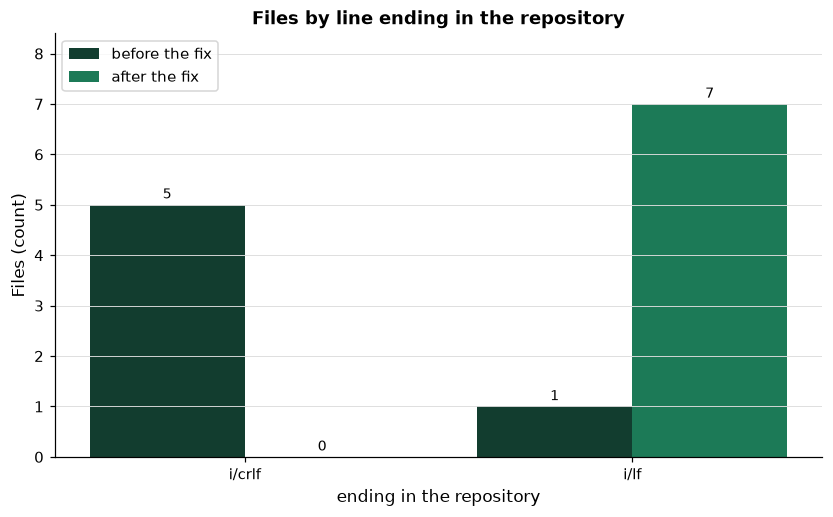

,lines changed
file,
.gitattributes,1
.gitignore,8
bondmath.py,"1,144"
bondmath_excel_reference.csv,614
bondmath_excel_reference_tvm.csv,308
test_bondmath.py,856


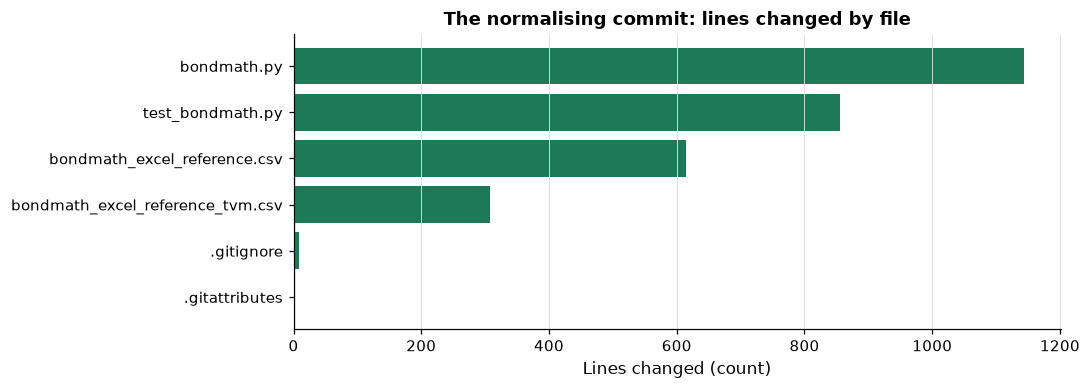

In [33]:
# the repository's ending of each file (the i/ column of git ls-files --eol), counted in the two recorded transcripts
def endings(stem):
    lines = (work / "course9_transcripts" / "day03" / f"{stem}.txt").read_text(encoding="ascii").splitlines()[3:]
    return pd.Series([line.split()[0] for line in lines]).value_counts()

by_ending = pd.DataFrame({"before the fix": endings("git_eol_before"), "after the fix": endings("git_eol_after")}).fillna(0).astype(int)
by_ending.index.name = "ending in the repository"
display(plotkit.styled(by_ending, [], "Files of the course's demo repo by line ending in the repository, before and after the fix"))
ax = plotkit.bars(by_ending, "Files by line ending in the repository", "Files (count)", fmt="{:,.0f}")
ax.set_ylim(0, by_ending.to_numpy().max() * 1.2)
plt.show()

# the normalising commit's diff stat, one line per file: "name | lines changed ++--"
body = (work / "course9_transcripts" / "day03" / "git_normalise_stat.txt").read_text(encoding="ascii").splitlines()[3:]
stat = {line.split("|")[0].strip(): int(line.split("|")[1].split()[0]) for line in body if " | " in line}
normalised = pd.DataFrame({"lines changed": stat})
normalised.index.name = "file"
display(plotkit.styled(normalised, [], "Lines changed per file by the Normalise line endings commit, from the recorded diff stat"))
ax = plotkit.importance_bars(normalised.index, normalised["lines changed"], "The normalising commit: lines changed by file",
                             xlabel="Lines changed (count)")
plt.show()

* The first chart is the finding: five files `i/crlf` before, none after. The second is its price: the commit rewrites every line of those five files, and adds one line in `.gitattributes`. A reviewer reading this chart sees a line-ending change, not a code change.

* Before: 5 files `i/crlf`, `.gitignore`, `bondmath.py`, `bondmath_excel_reference.csv`, `bondmath_excel_reference_tvm.csv`, `test_bondmath.py`; only the README, written after day 2's mistake, is `i/lf`. That is day 2's finding, read from the repository itself.
* The fix is its own commit on `main`, "Normalise line endings": the same three commands as above, in a clone made with `core.autocrlf` false, so the clone's files were the repository's bytes. 6 files changed, 1,466 insertions and 1,465 deletions, close to day 2's pull request in reverse. Read without the carriage returns (`git diff --ignore-cr-at-eol`), the commit adds `.gitattributes` and nothing else: every other line is the same text.
* After: every file `i/lf`, under the rule, in every fresh clone, whatever `core.autocrlf` says on the machine that commits next. A rule in the repository beats a setting on each laptop.

### File names

Q. A test that opens `Bondmath_Excel_Reference.csv` when the file is `bondmath_excel_reference.csv`: plant it in a copy of the tests, in a folder of its own, and run it here.

In [34]:
# a copy of the public files, with one file name written in another case inside the tests
copy = work / "case_check"
copy.mkdir(exist_ok=True)
for name in ["bondmath.py", "bondmath_excel_reference.csv", "bondmath_excel_reference_tvm.csv"]:
    shutil.copy(work / name, copy / name)
text = (work / "test_bondmath.py").read_text(encoding="utf-8")
(copy / "test_bondmath.py").write_text(text.replace('"bondmath_excel_reference.csv"', '"Bondmath_Excel_Reference.csv"'),
                                       encoding="utf-8")
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no",
                         "test_bondmath.py"], cwd=copy, capture_output=True, text=True)
print(f"on this machine: {result.stdout.strip().splitlines()[-1]}")

on this machine: 40 passed in 1.66s


* Every test passes on Windows, whose file names ignore case. On the Linux runner the same tests stop with `FileNotFoundError`. (In Colab, which is Linux, this cell already fails that way.)

Q. Catch it before a runner does: compare every `.csv` name the tests write with the folder's real names, case and all.

In [35]:
import re


def case_problems(folder, test_file):
    """The .csv names a test file writes in quotes that are not, letter for letter, a file in the folder."""
    names = set(os.listdir(folder))
    written = re.findall(r"[\"']([\w.-]+\.csv)[\"']", (Path(folder) / test_file).read_text(encoding="utf-8"))
    return sorted(name for name in set(written) if name not in names)


print(f"the planted copy: {case_problems(copy, 'test_bondmath.py')}")
print(f"the work folder:  {case_problems(work, 'test_bondmath.py')}")

the planted copy: ['Bondmath_Excel_Reference.csv']
the work folder:  []


* One name in the copy, none in the work folder. The rule that follows: write a file's name exactly as it is on disk, and keep names lower case. The case check runs here, on Windows; a runner never needs it, because there the test itself fails.

## 3.6 The Matrix

**How it works.** A matrix turns one job into several. GitHub takes each value of each key you list, here the Python version, and starts one copy of the job for it, all at once, on separate runners. Each copy puts its value where the steps can read it (`matrix.python-version`), so the same steps run on different Pythons. By default, when one copy fails GitHub cancels the copies still running: that is **fail-fast**. You control the keys and their values; what comes out is one result for each combination, shown as `test (3.12)` and `test (3.13)`.

`strategy: matrix` runs the same job once for each value: here twice, `test (3.12)` and `test (3.13)`, side by side on two runners.

* **3.13** is the course's Python (your local 3.13.8).
* **3.12** is the Python of a Hugging Face ZeroGPU Space, where day 10 puts the desk's app. A test that passes on 3.13 and fails on 3.12 is found here, not on the Space.

The runner does not install your exact 3.13.8: setup-python installs the newest 3.13 it has. The course's recorded runs got **3.13.16** for 3.13 and **3.12.15** for 3.12.

Q. Write the matrix for another set of Pythons: what does `workflow_text` produce for 3.11, 3.12, and 3.13?

In [36]:
three = deploykit.workflow_text(python_versions=("3.11", "3.12", "3.13"))
print([line.strip() for line in three.splitlines() if line.strip().startswith("python-version: [")])
print(f"read back: {yaml.safe_load(three)['jobs']['test']['strategy']['matrix']['python-version']}")

['python-version: ["3.11", "3.12", "3.13"]']
read back: ['3.11', '3.12', '3.13']


* Three quoted versions, read back as text: three jobs per run. Each job is billed as its own minutes on a private repository; on a public one they are free (the platform line in section 3.1).
* A matrix has one more behaviour, **fail-fast**, on by default: when one job fails, GitHub cancels the others still running. Section 3.7's red runs show it.

## 3.7 The Course's Runs on GitHub

### On your own account: CI for `pfi-bondmath`

Do this after the course's walk-through below, in PowerShell, in the `pfi-bondmath` repo of days 1 and 2. First the line-ending rule, as in section 3.5:

```powershell
Set-Location "$HOME\projects\pfi-bondmath"
git switch main
git pull --ff-only
Set-Content -Path .gitattributes -Value "* text=auto eol=lf"
git add .gitattributes
git add --renormalize .
git commit -m "Normalise line endings"
```

Then the workflow, written by your own `deploykit`, and the requirements file the runner installs (both lines are needed: section 3.7 shows why):

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -c "import deploykit, pathlib; p = pathlib.Path.home() / 'projects' / '{PUBLIC}' / '.github' / 'workflows'; p.mkdir(parents=True, exist_ok=True); (p / 'tests.yml').write_text(deploykit.workflow_text(), newline='\n')"
Set-Location "$HOME\projects\{PUBLIC}"
Set-Content -Path requirements.txt -Value "numpy=={c9lib.PINNED['numpy']}", "pytest=={c9lib.PINNED['pytest']}"
git add .github/workflows/tests.yml requirements.txt
git commit -m "{WORKFLOW_COMMIT}"
git push
```

Open the repository on GitHub and click the **Actions** tab: the run appears within a few seconds, with one job per Python. Click a job to read its log, step by step. With the GitHub CLI, `gh run list` lists the runs and `gh run view <number> --log` prints a log.

Q. The course pushed the same workflow to its throwaway repo `{DEMO_REPO}`, without a requirements file. What did Git print?

In [37]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day03" / "git_push_workflow.txt", max_lines=6)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> git push origin main

To https://github.com/student/pfi-deploy-demo.git
   a457905..47ad2de  main -> main


* The push itself: one commit onto `main`. Nothing in Git's output mentions the workflow; GitHub reads the file after the push arrives.

Q. The first run was red. Read the failed step of its log (`gh run view <run> --log-failed`, which prints only the steps that failed).

In [38]:
# recorded transcript: a helper that prints one step of a recorded Actions log, read from its file
import re

# each line of gh run view --log is: the job, a tab, the step, a tab, a timestamp, then the text the runner printed
LOG_LINE = re.compile(r"^[^\t]*\t([^\t]*)\t\S*?(\d{4}-\d\d-\d\dT[\d:.]+Z) ?(.*)$")
COLOUR = re.compile(r"\x1b\[[0-9;]*m")


def log_step(path, step, keep=None):
    """Print one step of a recorded gh run view --log, without the job, the step name, and the timestamp that start
    every line, and without the terminal's colour codes.

    Inputs: path, the transcript file; step, the step's name as the log writes it ("Run actions/checkout@v7");
    keep, a regular expression: when given, only the lines it matches are printed, and the count says so.
    """
    lines = Path(path).read_text(encoding="ascii").splitlines()[3:]
    body = [COLOUR.sub("", m.group(3)) for m in map(LOG_LINE.match, lines) if m and m.group(1) == step]
    shown = [line for line in body if keep is None or re.search(keep, line)]
    print(f"step '{step}': {len(body)} lines in the log, {len(shown)} shown")
    for line in shown:
        print("  " + line)


GREEN = work / "course9_transcripts" / "day03" / "gh_run_green.txt"
steps = list(dict.fromkeys(m.group(1) for m in map(LOG_LINE.match, GREEN.read_text(encoding="ascii").splitlines()[3:]) if m))
print(f"the green log: {len(steps)} steps")
for number, name in enumerate(steps, start=1):
    print(f"  {number}. {name}")

the green log: 9 steps
  1. Set up job
  2. Run actions/checkout@v7
  3. Run actions/setup-python@v7
  4. Run python -m pip install --upgrade pip
  5. Run python -m pip install -r requirements.txt
  6. Run python -m pytest -q test_bondmath.py
  7. Post Run actions/setup-python@v7
  8. Post Run actions/checkout@v7
  9. Complete job


In [39]:
# recorded transcript: the first run, red
RED = work / "course9_transcripts" / "day03" / "gh_run_red.txt"
print(RED.read_text(encoding="ascii").splitlines()[1])
log_step(RED, "Run python -m pip install -r requirements.txt")

command: gh run view 38236890266 --log-failed
step 'Run python -m pip install -r requirements.txt': 13 lines in the log, 13 shown
  ##[group]Run python -m pip install -r requirements.txt
  python -m pip install -r requirements.txt
  shell: /usr/bin/bash -e {0}
  env:
    pythonLocation: /opt/hostedtoolcache/Python/3.12.15/x64
    PKG_CONFIG_PATH: /opt/hostedtoolcache/Python/3.12.15/x64/lib/pkgconfig
    Python_ROOT_DIR: /opt/hostedtoolcache/Python/3.12.15/x64
    Python2_ROOT_DIR: /opt/hostedtoolcache/Python/3.12.15/x64
    Python3_ROOT_DIR: /opt/hostedtoolcache/Python/3.12.15/x64
    LD_LIBRARY_PATH: /opt/hostedtoolcache/Python/3.12.15/x64/lib
  ##[endgroup]
  ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
  ##[error]Process completed with exit code 1.


* The helper lists the green log's 9 steps first, for later; then the red one. `##[group]` and `##[endgroup]` are GitHub's markers for a block the web page folds. The command, then `shell: /usr/bin/bash -e {0}`: bash, as section 3.3 said. The `env:` lines say where setup-python put Python 3.12.15.
* Then the reason, in pip's own words: `Could not open requirements file`. The workflow installs `requirements.txt`, and the demo repo had none: day 1's public folder never needed one. The log shows only the job `test (3.12)`; the job `test (3.13)` was **cancelled** by fail-fast, not failed.
* The fix the course pushed: a `requirements.txt` holding `pytest==9.1.1`, the one package the tests import. Or so it seemed.

Q. The second run was red too. Read the pytest step.

In [40]:
# recorded transcript: the second run, red
RED_2 = work / "course9_transcripts" / "day03" / "gh_run_red_2.txt"
print(RED_2.read_text(encoding="ascii").splitlines()[1])
log_step(RED_2, "Run python -m pytest -q test_bondmath.py", keep=r"^[.F]+ |passed|FAILED|Error|^>|^____")

command: gh run view 38236944176 --log-failed
step 'Run python -m pytest -q test_bondmath.py': 25 lines in the log, 7 shown
  .............................F..........                                 [100%]
  __________________________ test_matches_numpy_interp ___________________________
  >       import numpy as np  # numpy is in the course requirements; bondmath itself does not use it
  E       ModuleNotFoundError: No module named 'numpy'
  test_bondmath.py:327: ModuleNotFoundError
  FAILED test_bondmath.py::test_matches_numpy_interp - ModuleNotFoundError: No module named 'numpy'
  1 failed, 39 passed in 2.18s


* `1 failed, 39 passed`. The failing test, `test_matches_numpy_interp`, starts with `import numpy as np`, line 327 of `test_bondmath.py`: Course 2 checked `bondmath`'s interpolation against NumPy's. `bondmath` itself uses only the standard library, so the course's laptop never showed that the **tests** need NumPy: it was always installed there.
* That is exactly what CI is for. The runner starts with nothing, so a requirements file must list what the tests import as well as what the code imports. Day 4 finds such lists by reading the imports.
* The fix: `numpy==2.5.3` added, at the course's pin.

Q. The third run was green. Read its log, section by section: the machine, the checkout, the Python, the install, the tests.

In [41]:
# recorded transcript: the third run, green: one job's log, test (3.13)
print(GREEN.read_text(encoding="ascii").splitlines()[1])
setup = "Set up job"
log_step(GREEN, setup, keep=r"^Ubuntu$|^\d+\.\d+\.\d+$|^LTS$|^Image: |^Secret source")
log_step(GREEN, "Run actions/checkout@v7", keep=r"^  repository: |^  token: |^Working directory|^Switched to")
log_step(GREEN, "Run actions/setup-python@v7", keep=r"python-version|token|Successfully set up")
log_step(GREEN, "Run python -m pip install -r requirements.txt", keep=r"^shell: |^Collecting (numpy|pytest)==|^Successfully installed")
log_step(GREEN, "Run python -m pytest -q test_bondmath.py", keep=r"^shell: |passed")

command: gh run view --job 114770291285 --log
step 'Set up job': 34 lines in the log, 5 shown
  Ubuntu
  24.04.5
  LTS
  Image: ubuntu-24.04
  Secret source: Actions
step 'Run actions/checkout@v7': 86 lines in the log, 4 shown
    repository: student/pfi-deploy-demo
    token: ***
  Working directory is '/home/runner/work/pfi-deploy-demo/pfi-deploy-demo'
  Switched to a new branch 'main'
step 'Run actions/setup-python@v7': 12 lines in the log, 3 shown
    python-version: 3.13
    token: ***
  Successfully set up CPython (3.13.16)
step 'Run python -m pip install -r requirements.txt': 34 lines in the log, 4 shown
  shell: /usr/bin/bash -e {0}
step 'Run python -m pytest -q test_bondmath.py': 13 lines in the log, 2 shown
  shell: /usr/bin/bash -e {0}
  40 passed in 2.14s


Q. How long is each step's log? Count the lines of every step of the green run.

,lines in the log
step,
Set up job,34
Run actions/checkout@v7,86
Run actions/setup-python@v7,12
Run python -m pip install --upgrade pip,12
Run python -m pip install -r requirements.txt,34
Run python -m pytest -q test_bondmath.py,13
Post Run actions/setup-python@v7,1
Post Run actions/checkout@v7,32
Complete job,1


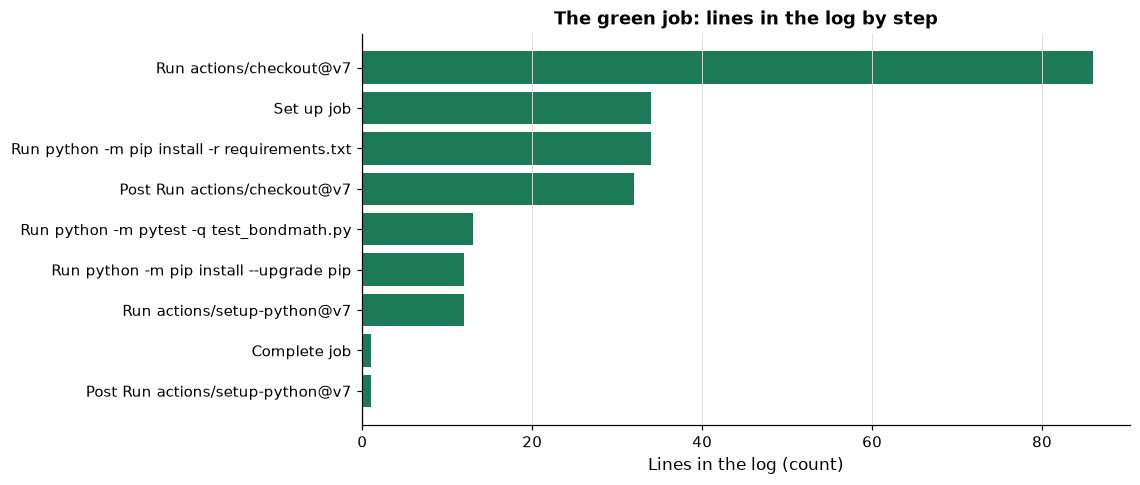

In [42]:
# the lines each step wrote to the green job's log, from the recorded transcript
per_step = pd.Series([m.group(1) for m in map(LOG_LINE.match, GREEN.read_text(encoding="ascii").splitlines()[3:]) if m]).value_counts()
step_lines = pd.DataFrame({"lines in the log": per_step[steps]})
step_lines.index.name = "step"
display(plotkit.styled(step_lines, [], "Lines each step wrote to the log of the green job, test (3.13)"))
ax = plotkit.importance_bars(step_lines.index, step_lines["lines in the log"], "The green job: lines in the log by step",
                             xlabel="Lines in the log (count)")
plt.show()

* The checkout writes the most, 86 lines; the job's setup and the install follow at 34 each. The step that ran the tests writes 13, because `pytest -q` prints little when everything passes. On a red run the failing step is the one to read.

Q. The log's lines carry timestamps. Draw the job as a timeline: when each step started, and how long it lasted.

,starts at (s),lasts (s)
step,,
Set up job,0.0,0.8
actions/checkout@v7,0.8,0.6
actions/setup-python@v7,1.4,0.2
python -m pip install --upgrade pip,1.6,2.8
python -m pip install -r requirements.txt,4.4,4.3
python -m pytest -q test_bondmath.py,8.7,2.7
Post actions/setup-python@v7,11.4,0.1
Post actions/checkout@v7,11.5,0.3
Complete job,11.8,0.0


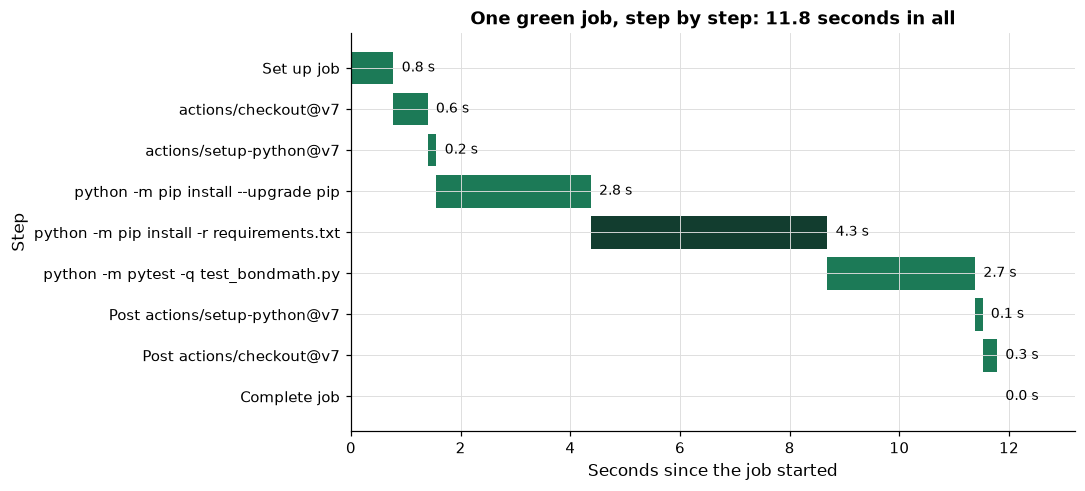

job time: 11.8 s; longest step: python -m pip install -r requirements.txt (4.3 s); tests: 2.7 s


In [43]:
# the timeline of the green job: a step starts at its first log line and lasts until the next step starts
stamps = pd.DataFrame([(m.group(1), pd.Timestamp(m.group(2))) for m in map(LOG_LINE.match, GREEN.read_text(encoding="ascii").splitlines()[3:]) if m],
                      columns=["step", "time"])
starts = stamps.groupby("step", sort=False)["time"].min()
begin = starts.iloc[0]
start_s = (starts - begin).dt.total_seconds().to_numpy()
# the last step lasts until the job's last log line
end_s = list(start_s[1:]) + [max((stamps["time"].max() - begin).total_seconds(), start_s[-1])]
timeline = pd.DataFrame({"starts at (s)": start_s, "lasts (s)": [e - b for b, e in zip(start_s, end_s)]},
                        index=pd.Index([step.replace("Run ", "") for step in starts.index], name="step"))
display(plotkit.styled(timeline, [], "The green job's steps on a timeline: when each started and how long it lasted, in seconds", fmt="{:.1f}"))

longest = timeline["lasts (s)"].idxmax()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(timeline.index, timeline["lasts (s)"], left=timeline["starts at (s)"],
        color=[plotkit.GREEN_DARK if step == longest else plotkit.GREEN for step in timeline.index])
for position, (step, row) in enumerate(timeline.iterrows()):
    ax.text(row["starts at (s)"] + row["lasts (s)"] + 0.15, position, f"{row['lasts (s)']:.1f} s", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, end_s[-1] * 1.12)
ax.set_xlabel("Seconds since the job started")
ax.set_ylabel("Step")
ax.set_title(f"One green job, step by step: {end_s[-1]:.1f} seconds in all")
plt.tight_layout()
plt.show()
print(f"job time: {end_s[-1]:.1f} s; longest step: {longest} ({timeline.loc[longest, 'lasts (s)']:.1f} s); tests: {timeline.loc['python -m pytest -q test_bondmath.py', 'lasts (s)']:.1f} s")

* Read the bars left to right as the job's clock; the dark bar is the longest step. The runner is ready, the checkout and Python take about a second between them, and then the installs take the longest stretch: pip upgrades itself, then downloads and installs the pinned packages on a machine that starts empty. The tests, the step the whole run exists for, are about a quarter of the job. The two **Post** steps at the end clean up the checkout and Python, and the job closes with a step too short to draw.
* A run that takes minutes is a run to read step by step: this chart tells you which step to open first. The times are this one run's, on one day, from the log's own timestamps.

* **The machine**: Ubuntu 24.04.5 LTS, the image `ubuntu-24.04`; `ubuntu-latest` is a label, and GitHub moves it to a newer Ubuntu from time to time. "Secret source: Actions" is where the job would read secrets from (section 3.8).
* **The checkout**: the demo repo, masked to `student`, into a working directory under `/home/runner`, on a branch `main`. The token the checkout used is printed as `***`.
* **The Python**: setup-python read `python-version: 3.13` from the matrix and set up CPython 3.13.16.
* **The install**: pip collected the two pinned lines and their dependencies: `Successfully installed iniconfig-2.3.1 numpy-2.5.3 packaging-26.3 pluggy-1.6.0 pygments-2.21.0 pytest-9.1.1`.
* **The tests**: `40 passed`, the same count as section 3.3 on this machine. The whole log of this one job is 225 lines; the other job's is the same with 3.12.

Q. And the history of the repo's runs, as `gh run list` prints it with `--json`?

In [44]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day03" / "gh_run_list.txt", max_lines=4)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> gh run list --json databaseId,displayTitle,headBranch,event,status,conclusion,createdAt
[{"conclusion":"success","createdAt":"2026-10-12T10:33:33Z","databaseId":38237082499,"displayTitle":"Add numpy, which one test imports","event":"push","headBranch":"main","status":"completed"},{"conclusion":"failure","createdAt":"2026-10-12T10:32:12Z","databaseId":38236944176,"displayTitle":"Add the requirements file the workflow installs","event":"push","headBranch":"main","status":"completed"},{"conclusion":"failure","createdAt":"2026-10-12T10:31:41Z","databaseId":38236890266,"displayTitle":"Run the tests on every push and pull request","event":"push","headBranch":"main","status":"completed"}]


In [45]:
# recorded transcript: the run list as a table
import json

text = (work / "course9_transcripts" / "day03" / "gh_run_list.txt").read_text(encoding="ascii")
runs = pd.DataFrame(json.loads(text[text.index("["):]))
print(runs[["createdAt", "displayTitle", "event", "conclusion"]].sort_values("createdAt").to_string(index=False))

           createdAt                                    displayTitle event conclusion
2026-10-12T10:31:41Z    Run the tests on every push and pull request  push    failure
2026-10-12T10:32:12Z Add the requirements file the workflow installs  push    failure
2026-10-12T10:33:33Z               Add numpy, which one test imports  push    success


Q. Draw the three runs in the order they happened.

,conclusion,minutes since the first run
displayTitle,,
Run the tests on every push and pull request,failure,0.0
Add the requirements file the workflow installs,failure,0.5
"Add numpy, which one test imports",success,1.9


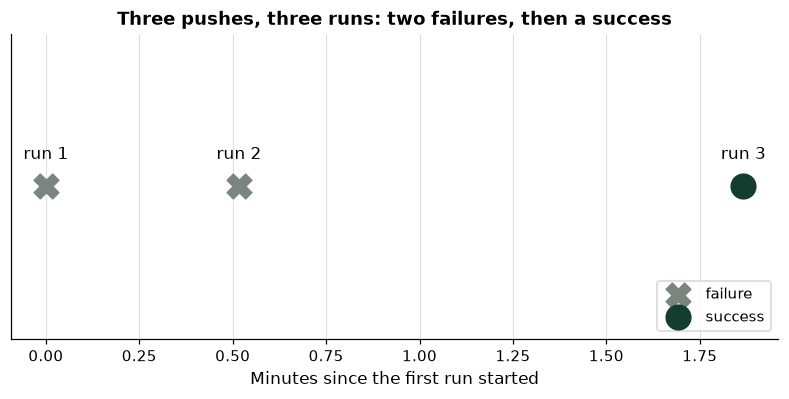

In [46]:
# minutes since the first run, one point per run, marked by its conclusion
ordered = runs.sort_values("createdAt").reset_index(drop=True)
ordered["minutes since the first run"] = (pd.to_datetime(ordered["createdAt"]) - pd.to_datetime(ordered["createdAt"]).iloc[0]).dt.total_seconds() / 60
display(plotkit.styled(ordered[["displayTitle", "conclusion", "minutes since the first run"]].set_index("displayTitle"), [],
                       "The repo's three Actions runs in the order they started", fmt="{:.1f}"))
fig, ax = plt.subplots(figsize=(9, 3.6))
for conclusion, marker, colour in (("failure", "X", plotkit.GREY), ("success", "o", plotkit.GREEN_DARK)):
    rows = ordered[ordered["conclusion"] == conclusion]
    ax.scatter(rows["minutes since the first run"], [0] * len(rows), s=260, marker=marker, color=colour, label=conclusion, zorder=3)
for number, (_, run) in enumerate(ordered.iterrows(), start=1):
    ax.annotate(f"run {number}", (run["minutes since the first run"], 0), xytext=(0, 18), textcoords="offset points", ha="center")
ax.set_yticks([])
ax.set_ylim(-1, 1)
ax.set_xlabel("Minutes since the first run started")
ax.set_title("Three pushes, three runs: two failures, then a success")
ax.legend(loc="lower right")
plt.show()

* Run 1 failed on a missing requirements file, run 2 on a missing NumPy, and run 3 passed: each failure took one commit to fix, and all three runs started within two minutes. The chart is the history of the repository learning what the runner needs.

* 3 runs, one per push to `main`, each titled with its commit's message: failure, failure, success. On GitHub the same three show as two red crosses and a green tick in the Actions tab and beside each commit. Day 5 turns a list like this into a pass rate.
* Read the order: the workflow arrived first, and was red until the repository held everything the runner needed. A red run is not a broken bond model; it is a message about the repository, and the log names it.

## 3.8 Secrets in CI

**How it works.** An Actions secret is a named value stored, encrypted, in the repository's settings and handed to a job only when a step asks for it by name. A step reads it as an expression, `${{ secrets.NAME }}`, which GitHub replaces on the runner, so the value is never in the file or in the repository. GitHub also scans the log for the values of the secrets it knows and replaces them with `***`, but only for the exact value, so a transformed copy of it passes through. You control the names and which steps read them; what comes out is a job that can use a credential, and a log that must never show it.

The course's tests need no secret. A later workflow might: a token to publish a package, or to deploy. GitHub keeps such values as **Actions secrets**, set in the repository's **Settings**, and a workflow reads one by name as `${{ secrets.NAME }}`, never by typing the value into the file.

What the platform does with them, as its pages state (docs.github.com/en/actions/concepts/security/secrets and docs.github.com/en/actions/reference/security/secure-use, read 2026-10-12):

* "GitHub Actions automatically redacts the contents of all GitHub secrets that are printed to workflow logs." The green log's `token: ***` lines are this: the token the checkout used, hidden (2 such lines in the two steps above).
* "Because there are multiple ways a secret value can be transformed, this redaction is not guaranteed." A secret that is "transformed in some way (such as Base64 or URL-encoded)" is not hidden, and "structured data can cause secret redaction within logs to fail".

So the rule is the one from Course 3: never print a secret, not even to see whether it loaded. `check_workflow` reports a `run` line that echoes a `secrets.` expression (section 3.4's fourth copy). On a public repository, anyone can read the logs.

## Excel Side by Side

None today. Excel has no workflow, no runner, and no test that runs on every change: a workbook's checks run when someone opens it and looks. Week 3 brings Excel back, where it reads what a service logs.

## Save the Day with Git

The module commit was section 3.4's. The workflow file is still uncommitted, and the runner needs the requirements file the course learnt it needs.

Q. Write `requirements.txt`, commit it with the workflow, show what the commit holds, and push.

In [47]:
# one package per line, pinned; written with LF endings, as the repository's rule now stores every text file
(work / "requirements.txt").write_text('numpy==2.5.3\npytest==9.1.1\n', encoding="utf-8", newline="\n")
print((work / "requirements.txt").read_text(encoding="utf-8"))

numpy==2.5.3
pytest==9.1.1



In [48]:
!git -C "{work}" add .github/workflows/tests.yml requirements.txt
!git -C "{work}" commit -q -m "Run the tests on every push and pull request"
!git -C "{work}" show --stat --format=%s HEAD
!git -C "{work}" push -q
!git -C "{work}" status -sb

Run the tests on every push and pull request

 .github/workflows/tests.yml | 16 ++++++++++++++++
 requirements.txt            |  2 ++
 2 files changed, 18 insertions(+)


## main...origin/main
?? plotkit.py


In [49]:
# the day's commits, newest first
!git -C "{work}" log --format=%s

Run the tests on every push and pull request
Normalise line endings
deploykit day 3: workflow_text, workflow_steps, check_workflow, 14 tests
deploykit day 2: conflict_files, squashed from its branch; 10 tests


* Two files: the workflow and the requirements. On `remote.git` nothing runs, since it is a folder and not GitHub; pushed to a GitHub repo, this commit starts a run.

## Bring It Home

In your own `my_bondmath`, open a PowerShell terminal in VS Code, with the course environment active.

**Step 1.** Paste the code of today's three `%%writefile -a` cells, without their first lines: sections 3.2 and 3.4 at the end of `deploykit.py`, in that order, and section 3.4's tests at the end of `test_deploykit.py`. Run the tests:

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -m pytest -q test_deploykit.py
```

The last line says `14 passed`.

**Step 2.** Commit:

```powershell
git add deploykit.py test_deploykit.py
git commit -m "deploykit day 3: workflow_text, workflow_steps, check_workflow, 14 tests"
```

**Step 3.** CI for `pfi-bondmath`: the "On your own account" steps of section 3.7. When the run is green, open the commit on GitHub: the green tick beside it links to the run. If it is red, read the failed step's log first, as section 3.7 did, before changing anything.

**In Colab**, the notebook runs as it is. The PowerShell steps are for your own machine.

## You Can Now

* Say what CI does: a fresh Linux machine runs your tests on every push and pull request.
* Write a workflow with `workflow_text`, read it with `workflow_steps`, and check it with `check_workflow`.
* Read a workflow's bash line by line, and type the same commands in PowerShell.
* Quote every version in YAML, and know that `on` is read as True.
* Fix line endings in the repository with `.gitattributes`, and keep file names in their exact case.
* Run the tests on two Pythons with a matrix, and know what fail-fast cancels.
* Read a red run's log, find the reason, and fix it in the repository.

Next, day 4: what a server installs, and why the server's requirements are not the course's.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It defines `check`, a small function that marks your answers, and imports PyYAML.

In [50]:
import yaml

def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")


print(f"the course's workflow: {len(deploykit.workflow_steps(deploykit.workflow_text()))} steps")

the course's workflow: 5 steps


### Exercise 1

Q. Add a step that prints the runner's Python, `python --version`, right after the `setup-python` step: insert the line `      - run: python --version` (six spaces, a dash) into the course's workflow text. Store the new text's number of steps from `deploykit.workflow_steps`, and the list `deploykit.check_workflow` returns, as a tuple in **ex1_answer**.

In [51]:
ex1_answer = ...

In [52]:
check("Exercise 1 steps and problems", ex1_answer, (6, []))

Exercise 1 steps and problems: not attempted yet


### Exercise 2

Q. A workflow that runs only on pull requests: change the trigger line to `on: [pull_request]`. Read the new text with `yaml.safe_load` and store what it holds under the trigger key in **ex2_triggers** (remember section 3.4: the key `on` is not read as the text `"on"`). Does `check_workflow` report anything?

In [53]:
ex2_triggers = ...

In [54]:
check("Exercise 2 the triggers", ex2_triggers, ["pull_request"])

Exercise 2 the triggers: not attempted yet


### Exercise 3

Q. Add a function to your module. `jobs_in(text)` returns a dictionary of every job of a workflow and the machine it runs on, its `runs-on` label, in the order of the file. Write the docstring first, then `test_jobs_in`, which adds a second job, `lint`, on `windows-latest`, to the course's workflow and checks both. Read the file through `_workflow`, so the key `on` is handled. Run pytest, reload the module, and store `deploykit.jobs_in(deploykit.workflow_text())` in **ex3_jobs**.

Write the function in the cell that starts with `%%writefile -a deploykit.py` and the test in the one that starts with `%%writefile -a test_deploykit.py`, and run each of those cells once.

In [55]:
%%writefile -a deploykit.py


# Exercise 3: write jobs_in(text) below this line

Appending to deploykit.py


In [56]:
%%writefile -a test_deploykit.py


# Exercise 3: write test_jobs_in() below this line

Appending to test_deploykit.py


In [57]:
# run pytest, reload the module, then list the jobs of the course's workflow
ex3_jobs = ...

In [58]:
check("Exercise 3 the jobs", ex3_jobs, {"test": "ubuntu-latest"})

Exercise 3 the jobs: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a check of a workflow's Python matrix, and give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The problems of a workflow's Python matrix, one sentence each; an empty list means none.

    Input: text, a workflow's YAML. For every job with a strategy matrix, every value of python-version must be
    read by yaml.safe_load as text equal to what the file holds: "3.10" stays "3.10". An unquoted 3.10 is read as
    the number 3.1, and setup-python is then asked for a different Python than the one written. Output: one
    sentence per version read as a number. Convention: write every version in quotes.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns an empty list on the course's workflow, and contains one bug.

In [59]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def matrix_problems(text):
    """The problems of a workflow's Python matrix, one sentence each; an empty list means none."""
    data = yaml.safe_load(text)
    problems = []
    for job, spec in data["jobs"].items():
        matrix = spec.get("strategy", {}).get("matrix", {})
        # every job with a matrix must say which Pythons it tests
        if matrix and "python-version" not in matrix:
            problems.append(f"job {job}: the matrix names no python-version")
    return problems

Q. Before you run the test: the planted matrix is `[3.10, 3.13]`, without quotes. What will YAML read, and how many problems will `matrix_problems` return?

Q. Test the function against its docstring before you trust it: both unquoted versions must be reported, and the course's quoted matrix must pass.

In [60]:
# the test, written from the docstring before the code is trusted
# a matrix written without quotes, as the assistant's own example workflow had it
planted = deploykit.workflow_text().replace('["3.12", "3.13"]', "[3.10, 3.13]")
read = yaml.safe_load(planted)["jobs"]["test"]["strategy"]["matrix"]["python-version"]
print(f"the file says [3.10, 3.13]; YAML read {read}")
found = matrix_problems(planted)
assert len(found) == 2, f"matrix_problems found {len(found)} problems in a matrix of 2 unquoted versions"
assert matrix_problems(deploykit.workflow_text()) == [], "the course's quoted matrix must pass"
for problem in found:
    print(problem)

the file says [3.10, 3.13]; YAML read [3.1, 3.13]


AssertionError: matrix_problems found 0 problems in a matrix of 2 unquoted versions

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the number of problems the fixed version reports in **ex4_found**.

In [61]:
# fix the function above and run the test again, then store the answer
ex4_found = ...

In [62]:
check("Exercise 4 the problems found", ex4_found, 2)

Exercise 4 the problems found: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```